# ST1504 CA1 Part A: CNN Image Classification on EMNIST Letters

## 1. Problem Statement and Plan

The aim of Part A is to build a Convolutional Neural Network (CNN) that can classify handwritten character images from the provided dataset. Since the dataset contains image-like pixel values, a CNN is suitable because convolutional layers can learn local spatial patterns such as strokes, curves, edges, and shapes.

For this notebook, I will follow this workflow:

1. Load and inspect the dataset.
2. Check data quality, including label validity, duplicated rows, pixel range, class distribution, and image orientation.
3. Clean and preprocess the data.
4. Build a simple baseline CNN.
5. Evaluate the baseline model using accuracy, loss curves, confusion matrix, and class-level metrics.
6. Improve the model using better architecture, regularisation, and carefully chosen data augmentation.
7. Compare the models and choose the best final model based on validation performance.
8. Evaluate the final selected model on the test set.
9. Save the best model weights for submission.

This structure is used so that the final model is not just reported as a single accuracy number. Instead, the analysis explains what was checked, what choices were made, and whether each improvement actually helped.

### Importing Libraries

This cell imports the libraries needed for data handling, visualisation, model building, and evaluation. A fixed random seed is also set so that the train-validation-test split and model training are more reproducible.

In [1]:
# Core libraries
import os
import random
import string
import warnings

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

# Deep learning
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings("ignore")

# Make results more reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.10.0
GPU available: True


## 2. Data Loading

The dataset used is `emnist-letters.csv`, which was provided for this assignment. No external image data is used for training.

Each row should contain:
- 1 label column
- 784 pixel columns

Since 784 = 28 × 28, each row can be reshaped into a 28 by 28 grayscale image.

In [2]:
DATA_PATH = "emnist-letters.csv"

# Load as int16 to reduce memory usage
df = pd.read_csv(DATA_PATH, header=None, dtype=np.int16)

print("Dataset shape:", df.shape)
print("First 5 rows:")
display(df.head())

Dataset shape: (99040, 785)
First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,24,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-2,142,142,142,142,142,142,142,142,142,...,142,142,142,142,142,142,142,142,142,142
2,15,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,14,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,-2,120,120,120,120,120,120,120,120,120,...,120,120,120,120,120,120,120,120,120,120


### Initial Observation from the First 5 Rows

The dataset has **99,040 rows and 785 columns**. This matches the expected structure for an image classification dataset because:

- Column `0` contains the class label.
- Columns `1` to `784` contain the pixel values.
- Since `784 = 28 × 28`, each row can be reshaped into one **28 by 28 grayscale image**.

From the first 5 rows, the pixel values are mostly between **0 and 255**, which is expected for grayscale images. A value of `0` usually represents a dark pixel, while higher values represent lighter pixels.

However, I also noticed that some labels are negative, such as `-2`. This is a data quality issue because EMNIST letter labels should represent alphabet classes. For this project, only labels from **1 to 26** are valid because they can be mapped to letters **A to Z**.

Therefore, rows with labels outside the range **1 to 26** will be removed during data cleaning. This is important because invalid labels would confuse the CNN during supervised learning and affect the model’s performance.

## 3. Initial Data Inspection

Before building any model, I need to inspect the dataset carefully. This is important because a CNN can only learn properly if the input data and labels are valid.

The following checks will be performed:

1. Number of rows and columns.
2. Label values and whether they are in the expected range.
3. Pixel value range.
4. Missing values.
5. Duplicated rows.
6. Class distribution.

For EMNIST letters, the valid labels should represent 26 alphabet classes. In this notebook, labels 1 to 26 will be mapped to A to Z.

### Data Quality Check

In [3]:
label_col = 0
pixel_cols = df.columns[1:]

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of pixel columns:", len(pixel_cols))

# Check missing values
missing_count = df.isna().sum().sum()
print("Total missing values:", missing_count)

# Check duplicated rows
duplicate_count = df.duplicated().sum()
print("Total duplicated rows:", duplicate_count)

# Check label range
print("Minimum label:", df[label_col].min())
print("Maximum label:", df[label_col].max())

# Show label counts
label_counts = df[label_col].value_counts().sort_index()
print("Label distribution:")
display(label_counts.to_frame("count"))

# Check pixel value range
pixel_min = df[pixel_cols].min().min()
pixel_max = df[pixel_cols].max().max()

print("Minimum pixel value:", pixel_min)
print("Maximum pixel value:", pixel_max)

Number of rows: 99040
Number of columns: 785
Number of pixel columns: 784
Total missing values: 0
Total duplicated rows: 9465
Minimum label: -2
Maximum label: 26
Label distribution:


,count
0,
-2,4856
-1,5384
1,3396
2,3396
3,3419
4,3398
5,3437
6,3394
7,3385


Minimum pixel value: 0
Maximum pixel value: 345


### Data Quality Check Analysis

The dataset contains **99,040 rows and 785 columns**. This is suitable for the image classification task because column `0` stores the label, while the remaining **784 pixel columns** can be reshaped into a **28 × 28 grayscale image**.

There are **no missing values**, which means I do not need to handle empty cells before modelling. However, the dataset contains **9,465 duplicated rows** in the raw data. Duplicates should be checked because repeated samples can make the model appear to perform better than it actually does.

The label range is from **-2 to 26**, but for EMNIST letter classification, only labels **1 to 26** are valid because they map to the alphabet classes **A to Z**. The dataset contains invalid labels:

- Label `-2`: 4,856 rows
- Label `-1`: 5,384 rows

This means **10,240 rows** do not belong to the required 26-letter classification task. These rows must be removed because invalid labels cannot be correctly mapped to alphabet classes and would confuse the supervised learning process.

Another important observation is that the raw pixel maximum is shown as **345**, which is higher than the expected grayscale range of **0 to 255**. This suggests that the raw dataset contains some abnormal rows or non-standard values before cleaning. Therefore, I should not assume the raw dataset is fully clean. After filtering valid labels and preprocessing, I will check the final image range again before training the CNN.

### Clean invalid labels and duplicates

In [4]:
# Keep only valid alphabet labels
valid_df = df[(df[label_col] >= 1) & (df[label_col] <= 26)].copy()

print("Original number of rows:", len(df))
print("Rows after keeping labels 1 to 26:", len(valid_df))
print("Rows removed:", len(df) - len(valid_df))

# Check duplicated rows after removing invalid labels
valid_duplicate_count = valid_df.duplicated().sum()
print("Duplicated valid rows:", valid_duplicate_count)

# Remove duplicated rows
valid_df = valid_df.drop_duplicates().reset_index(drop=True)

print("Final cleaned dataset shape:", valid_df.shape)

Original number of rows: 99040
Rows after keeping labels 1 to 26: 88800
Rows removed: 10240
Duplicated valid rows: 2
Final cleaned dataset shape: (88798, 785)


### Data Cleaning Analysis

After filtering the dataset to keep only valid labels from **1 to 26**, the number of rows decreased from **99,040** to **88,800**. This means **10,240 invalid rows** were removed.

After this filtering step, there were only **2 duplicated valid rows**, which were also removed. The final cleaned dataset contains **88,798 rows and 785 columns**.

During the inspection, I identified and removed rows with invalid labels (-1, -2). These represent noise or "undeterminable" characters in the EMNIST dataset. Removing them ensures the model isn't trained on ambiguous features.

This cleaning step is important because the model should only learn from valid letter classes. If invalid labels such as `-1` and `-2` were kept, the CNN would be trained on classes that do not belong to the A to Z classification task. Removing invalid and duplicate rows improves the reliability of the training data and makes the later evaluation more meaningful. 

## 4. Class Distribution

Class distribution is important because an imbalanced dataset may cause the model to perform well on common classes but poorly on rare classes.

For this task, I will check whether each letter class has a similar number of samples. If the distribution is roughly balanced, accuracy is more meaningful. If it is highly imbalanced, metrics such as macro F1-score and class-level recall become even more important.

,label,letter,count
0,1,A,3396
1,2,B,3396
2,3,C,3419
3,4,D,3398
4,5,E,3437
5,6,F,3393
6,7,G,3385
7,8,H,3424
8,9,I,3428
9,10,J,3402


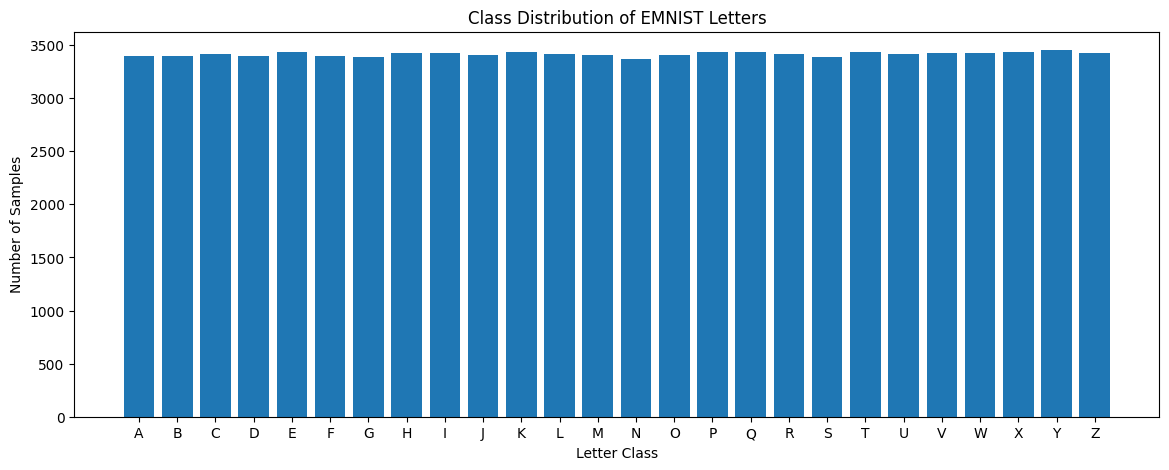

Minimum class count: 3365
Maximum class count: 3453
Difference: 88


In [5]:
# Convert labels to letters for readability
class_names = list(string.ascii_uppercase)

clean_label_counts = valid_df[label_col].value_counts().sort_index()
letter_counts = pd.DataFrame({
    "label": clean_label_counts.index,
    "letter": [class_names[i - 1] for i in clean_label_counts.index],
    "count": clean_label_counts.values
})

display(letter_counts)

plt.figure(figsize=(14, 5))
plt.bar(letter_counts["letter"], letter_counts["count"])
plt.title("Class Distribution of EMNIST Letters")
plt.xlabel("Letter Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

print("Minimum class count:", letter_counts["count"].min())
print("Maximum class count:", letter_counts["count"].max())
print("Difference:", letter_counts["count"].max() - letter_counts["count"].min())

### Class Distribution Analysis

The class distribution is very balanced across the 26 alphabet classes.

From the output:

- Minimum class count: **3,365**
- Maximum class count: **3,453**
- Difference: **88 samples**

The difference between the smallest and largest class is very small compared to the overall class sizes. This means no letter class heavily dominates the dataset.

This is useful because the model is less likely to become biased toward one or two majority classes. Since the classes are balanced, overall accuracy is a reasonable metric to use. However, accuracy alone is still not enough because some letters may be harder to classify than others. Therefore, I will later use a confusion matrix and class-level precision, recall, and F1-score to check which specific letters are commonly misclassified.

## 5. Preprocessing Overview

Before training the CNN, the cleaned data needs to be prepared into the correct format.

The main preprocessing steps are:

1. Separate labels from pixel columns.
2. Convert labels from **1–26** to **0–25** for Keras.
3. Reshape the 784 pixel columns into **28 × 28 × 1** grayscale images.
4. Correct the EMNIST image orientation if needed.
5. Normalise pixel values from **0–255** to **0–1**.

These steps are necessary because a CNN expects image-shaped input, not a flat row of 784 numbers.


### Image Reshaping and Orientation Check

Each image is stored as 784 pixel values. To use the image in a CNN, the 784 values must be reshaped into:

`28 × 28 × 1`

where:
- 28 = image height
- 28 = image width
- 1 = grayscale channel

However, EMNIST-style data can appear rotated or transposed when plotted directly. Therefore, I will visualise the raw image and the transposed image before deciding the final orientation.

This step is important because wrong image orientation can make the learning task harder for the CNN.

### Check orientation

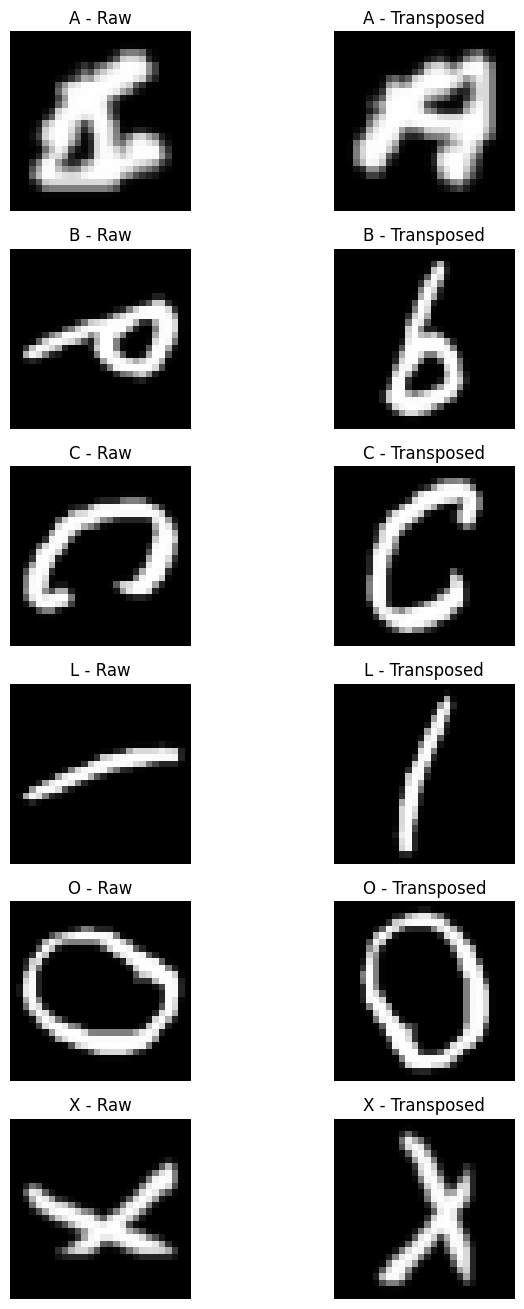

In [6]:
def label_to_letter(label):
    return class_names[int(label) - 1]

def show_orientation_examples(dataframe, labels_to_show=[1, 2, 3, 12, 15, 24]):
    plt.figure(figsize=(8, len(labels_to_show) * 2.2))
    
    plot_index = 1
    
    for label in labels_to_show:
        sample_row = dataframe[dataframe[label_col] == label].iloc[0]
        pixels = sample_row[pixel_cols].values
        
        raw_img = pixels.reshape(28, 28)
        transposed_img = raw_img.T
        
        plt.subplot(len(labels_to_show), 2, plot_index)
        plt.imshow(raw_img, cmap="gray")
        plt.title(f"{label_to_letter(label)} - Raw")
        plt.axis("off")
        plot_index += 1
        
        plt.subplot(len(labels_to_show), 2, plot_index)
        plt.imshow(transposed_img, cmap="gray")
        plt.title(f"{label_to_letter(label)} - Transposed")
        plt.axis("off")
        plot_index += 1
    
    plt.tight_layout()
    plt.show()

show_orientation_examples(valid_df)

### Orientation Decision

After comparing the raw and transposed images, the transposed version is used because the letters appear more upright and readable.

This step is not model tuning. It is a data preparation step because the CNN should receive images in the correct visual orientation.

### Prepare X and y

In [7]:
# Separate features and labels
X = valid_df[pixel_cols].values.astype("float32")
y = valid_df[label_col].values.astype("int64")

# Convert labels from 1-26 to 0-25
y = y - 1

# Reshape pixels to image format
X = X.reshape(-1, 28, 28, 1)

# Correct EMNIST orientation
X = np.transpose(X, (0, 2, 1, 3))

# Normalise pixels to 0-1
X = X / 255.0

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X minimum:", X.min())
print("X maximum:", X.max())
print("y minimum:", y.min())
print("y maximum:", y.max())

# Free memory
del df
del valid_df

X shape: (88798, 28, 28, 1)
y shape: (88798,)
X minimum: 0.0
X maximum: 1.0
y minimum: 0
y maximum: 25


### Final Preprocessing Analysis

After preprocessing, the feature matrix `X` has shape **(88,798, 28, 28, 1)**. This means there are **88,798 grayscale images**, where each image has height **28**, width **28**, and **1 colour channel**.

The label array `y` has shape **(88,798,)**, meaning there is one label for every image.

The labels were converted from **1–26** to **0–25** because Keras works well with zero-indexed integer class labels when using `sparse_categorical_crossentropy`.

The pixel values were normalised to the range **0 to 1**. The output confirms:

- X minimum: **0.0**
- X maximum: **1.0**

Normalisation is important because neural networks usually train more stably when the input values are kept within a small range. Without normalisation, large pixel values may make optimisation slower or less stable.


## 6. Visualising Representative Samples

Before modelling, I will display examples from different classes. This helps confirm that:
- the labels match the images,
- the image orientation is correct,
- the images are readable,
- and the dataset contains handwritten variation.

This is part of exploratory data analysis because visual inspection can reveal issues that summary statistics may miss.

### Show sample images 

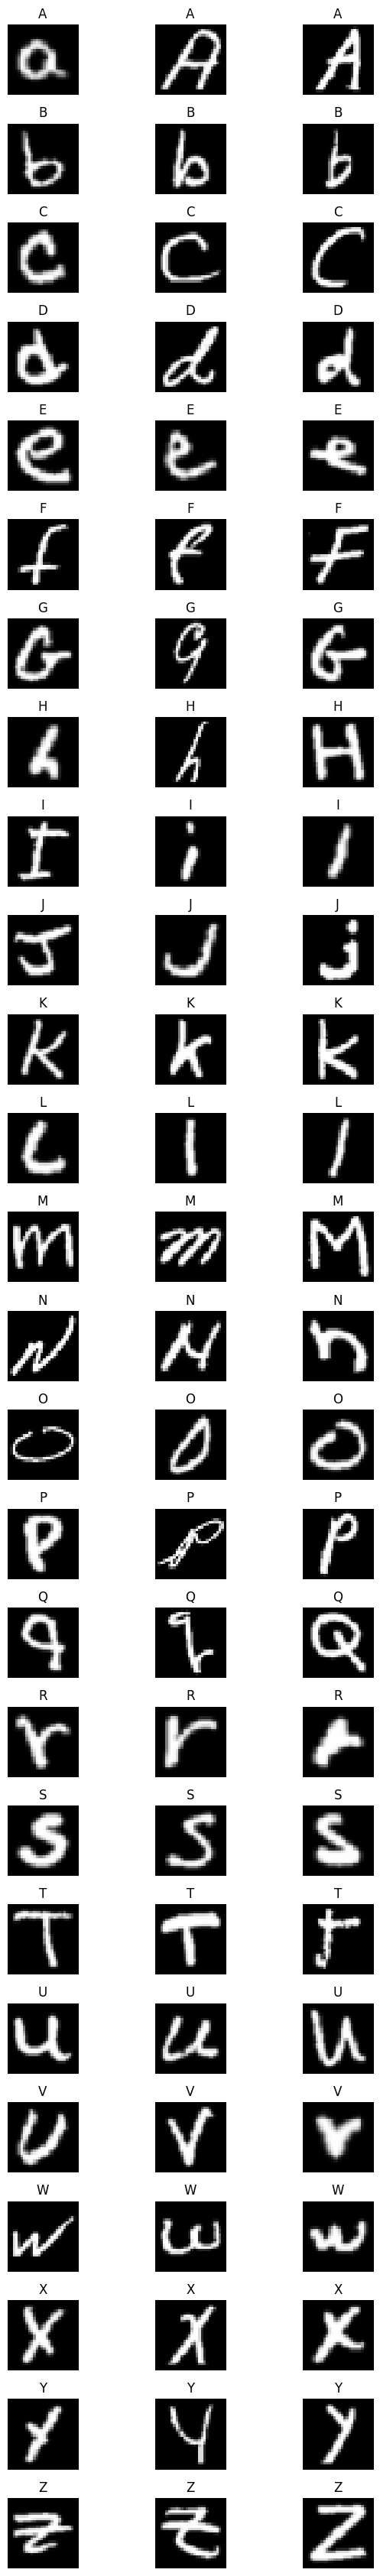

In [8]:
def show_letter_grid(X, y, class_names, samples_per_class=3):
    selected_classes = list(range(26))
    plt.figure(figsize=(samples_per_class * 2.2, 26 * 1.3))
    
    plot_index = 1
    
    for class_id in selected_classes:
        class_indices = np.where(y == class_id)[0]
        chosen_indices = np.random.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )
        
        for idx in chosen_indices:
            plt.subplot(26, samples_per_class, plot_index)
            plt.imshow(X[idx].squeeze(), cmap="gray")
            plt.title(class_names[class_id])
            plt.axis("off")
            plot_index += 1
    
    plt.tight_layout()
    plt.show()

show_letter_grid(X, y, class_names, samples_per_class=3)

### Sample Image Insight

The displayed samples show that the dataset contains handwritten alphabet letters. There is natural handwriting variation within each class. Some letters may look visually similar depending on handwriting style, such as:

- C and O
- I and L
- U and V
- M and N
- P and R

Because of these similarities, final evaluation should include a confusion matrix and class-level metrics instead of relying only on total accuracy.

## 7. Train, Validation, and Test Split

The dataset does not already provide a clear train, validation, and test split in the uploaded CSV. Therefore, I will create my own split.

I will use:
- 70% training data
- 15% validation data
- 15% test data

The validation set is used to compare models and tune choices. The test set is kept separate and should only be used for the final evaluation of the selected model.

A stratified split is used so that each letter class has a similar proportion in the training, validation, and test sets.

### Why a 70% / 15% / 15% Split Was Used

A **70% / 15% / 15%** split was used because it gives a good balance between training the CNN properly and evaluating it fairly.

The dataset after cleaning contains **88,798 images**, which is large enough to divide into three separate sets:

- **70% training set**: gives the model enough images to learn handwriting patterns such as strokes, curves, and letter shapes.
- **15% validation set**: gives enough unseen data to monitor training performance and compare different model versions.
- **15% test set**: gives a separate final dataset to evaluate the selected model fairly.

This split is suitable because the task has **26 classes**, from A to Z. If the validation or test set is too small, some classes may not be represented well, making the evaluation less reliable. With 15% for validation and 15% for testing, each set still contains many examples from every letter class.

A larger training split such as **80% / 10% / 10%** would give the model more training data, but the validation and test sets would be smaller. This may make the evaluation less stable, especially when checking class-level performance across 26 letters.

A split such as **60% / 20% / 20%** would give larger validation and test sets, but it would reduce the amount of training data available to the CNN. Since deep learning models usually need many training examples, this may weaken model learning.

Therefore, **70% / 15% / 15%** is a sensible choice because it keeps most of the data for training while still leaving enough data for validation and final testing. Stratified splitting was also used so that all 26 letter classes are fairly represented in each set.

In [9]:
# First split: train and temporary set
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Second split: validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

# Check class distribution in each split
split_summary = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "validation": pd.Series(y_val).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index()
})

split_summary.index = class_names
display(split_summary)

Training set: (62158, 28, 28, 1) (62158,)
Validation set: (13320, 28, 28, 1) (13320,)
Test set: (13320, 28, 28, 1) (13320,)


,train,validation,test
A,2377,510,509
B,2377,510,509
C,2393,513,513
D,2379,510,509
E,2406,516,515
F,2375,509,509
G,2370,507,508
H,2397,513,514
I,2400,514,514
J,2381,511,510


### Train, Validation, and Test Split Analysis

The cleaned dataset was split into three sets:

- Training set: **62,158 images**
- Validation set: **13,320 images**
- Test set: **13,320 images**

This follows a **70% / 15% / 15%** split.

The training set is used to teach the model. The validation set is used to monitor performance during training and compare different model versions. The test set is kept separate until the end so that it can provide a fair final evaluation of the selected model.

A stratified split was used, so each alphabet class keeps a similar proportion across the training, validation, and test sets. This is shown in the split table, where each class has roughly similar counts in each set. This is important because the model should be trained and evaluated on all classes fairly, not mostly on a few letters.

## 8. Baseline CNN Model

The first model is intentionally simple. A baseline model gives a reference point before making improvements.

The baseline CNN uses:
- Convolutional layers to learn local image patterns.
- Max pooling layers to reduce spatial size and keep important features.
- A dense layer for final classification.
- A softmax output layer because there are 26 possible letter classes.

The loss function used is `sparse_categorical_crossentropy` because this is a multi-class classification problem and the labels are stored as integers from 0 to 25.

The optimiser used is Adam because it is commonly used for deep learning and usually gives stable training without manually setting many parameters.

### Helper Functions

In [10]:
def plot_training_history(history, title):
    history_df = pd.DataFrame(history.history)
    
    plt.figure(figsize=(8, 5))
    plt.plot(history_df["accuracy"], label="Training Accuracy")
    plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(8, 5))
    plt.plot(history_df["loss"], label="Training Loss")
    plt.plot(history_df["val_loss"], label="Validation Loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

def summarise_history(history, model_name):
    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    final_train_accuracy = history.history["accuracy"][-1]
    final_val_accuracy = history.history["val_accuracy"][-1]
    
    return {
        "model": model_name,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "final_train_accuracy": final_train_accuracy,
        "final_val_accuracy": final_val_accuracy,
        "epochs_ran": len(history.history["loss"])
    }

def create_callbacks(model_name):
    checkpoint_path = f"{model_name}.weights.h5"
    
    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
    
    checkpoint = callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        mode="max"
    )
    
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
    
    return [early_stop, checkpoint, reduce_lr], checkpoint_path

### Build baseline CNN

In [11]:
def build_baseline_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(26, activation="softmax")
    ])
    
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 7, 64)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 3136)              0         
                                                                 
 dense (Dense)               (None, 128)               4

### Train baseline CNN

Epoch 1/20
486/486 [==============================] - 31s 15ms/step - loss: 0.7016 - accuracy: 0.7891 - val_loss: 0.4106 - val_accuracy: 0.8682 - lr: 0.0010
Epoch 2/20
486/486 [==============================] - 7s 14ms/step - loss: 0.3041 - accuracy: 0.9007 - val_loss: 0.2915 - val_accuracy: 0.9070 - lr: 0.0010
Epoch 3/20
486/486 [==============================] - 7s 14ms/step - loss: 0.2387 - accuracy: 0.9206 - val_loss: 0.2704 - val_accuracy: 0.9135 - lr: 0.0010
Epoch 4/20
486/486 [==============================] - 7s 14ms/step - loss: 0.2050 - accuracy: 0.9296 - val_loss: 0.2692 - val_accuracy: 0.9129 - lr: 0.0010
Epoch 5/20
486/486 [==============================] - 7s 15ms/step - loss: 0.1762 - accuracy: 0.9388 - val_loss: 0.2452 - val_accuracy: 0.9255 - lr: 0.0010
Epoch 6/20
486/486 [==============================] - 7s 14ms/step - loss: 0.1558 - accuracy: 0.9449 - val_loss: 0.2456 - val_accuracy: 0.9213 - lr: 0.0010
Epoch 7/20
486/486 [==============================] - 7s 15ms/s

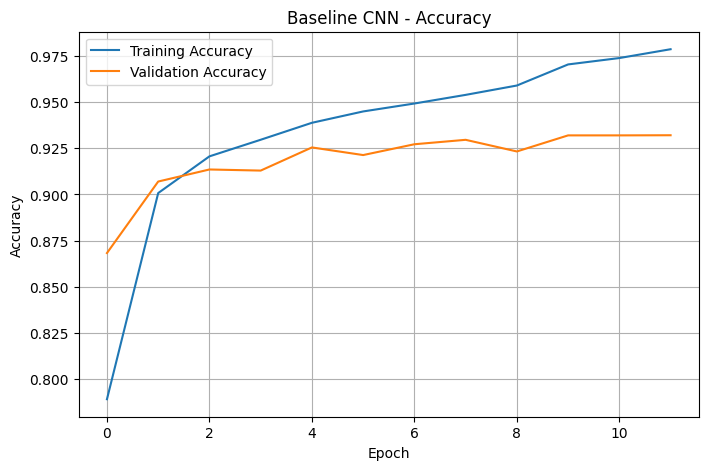

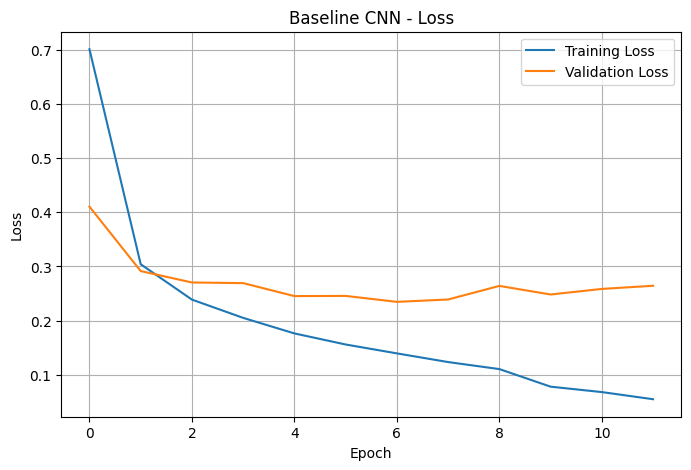

In [12]:
baseline_callbacks, baseline_checkpoint = create_callbacks("partA_baseline_cnn")

baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=baseline_callbacks,
    verbose=1
)

plot_training_history(baseline_history, "Baseline CNN")

## Baseline CNN Evaluation using Confusion Matrix

After training the baseline CNN, I evaluated it in more detail using the validation set.

Although accuracy gives an overall idea of model performance, it does not show which specific letters the model predicted correctly or wrongly. Therefore, I used a confusion matrix to analyse the baseline CNN at class level.

For this baseline evaluation, I used the **validation set** instead of the test set. This is because the test set should be kept separate for the final selected model. The validation set is suitable here because it allows me to understand the baseline model’s strengths and weaknesses before making improvements.

The confusion matrix helps answer the following questions:

- How many validation images were predicted correctly?
- How many validation images were predicted wrongly?
- Which letters were classified well?
- Which letters were commonly confused with other letters?

This gives a stronger evaluation than reporting only validation accuracy.

In [13]:
# Load the best saved baseline weights
baseline_model.load_weights(baseline_checkpoint)

# Evaluate baseline model on the validation set
baseline_val_loss, baseline_val_accuracy = baseline_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

# Predict class probabilities for validation images
baseline_pred_proba = baseline_model.predict(X_val)

# Convert probabilities into predicted class labels
baseline_pred = np.argmax(baseline_pred_proba, axis=1)

# Count correct and wrong predictions
baseline_correct = np.sum(baseline_pred == y_val)
baseline_wrong = np.sum(baseline_pred != y_val)
baseline_total = len(y_val)

# Display results clearly
print("Baseline CNN Validation Evaluation")
print("----------------------------------")
print("Validation Loss:", round(baseline_val_loss, 4))
print("Validation Accuracy:", round(baseline_val_accuracy, 4))
print("Total Validation Images:", baseline_total)
print("Correct Predictions:", baseline_correct)
print("Wrong Predictions:", baseline_wrong)
print("Correct Percentage:", round((baseline_correct / baseline_total) * 100, 2), "%")
print("Wrong Percentage:", round((baseline_wrong / baseline_total) * 100, 2), "%")

417/417 [==============================] - 2s 5ms/step
Baseline CNN Validation Evaluation
----------------------------------
Validation Loss: 0.2346
Validation Accuracy: 0.9272
Total Validation Images: 13320
Correct Predictions: 12350
Wrong Predictions: 970
Correct Percentage: 92.72 %
Wrong Percentage: 7.28 %


### Baseline Prediction Count Analysis

The baseline CNN validation evaluation reports:

- Validation loss: **0.2346**
- Validation accuracy: **92.72%**
- Total validation images: **13,320**
- Correct predictions: **12,350**
- Wrong predictions: **970**
- Wrong prediction rate: **7.28%**

The detailed baseline confusion matrix is based on the evaluated baseline weights, which produced **92.72% validation accuracy** and **970 wrong predictions**. In the final model comparison table, I also report the best validation accuracy observed during the baseline training history, which was **92.72%**. This small difference happens because Early Stopping and checkpointing can restore or save model weights based on different monitored validation metrics.

This means the baseline CNN correctly classified most validation images, which is a strong starting point for a simple CNN.

However, the model still misclassified **970** validation images. This is important because the assignment requires model quality analysis, not just reporting one accuracy score. The next step is to inspect where these mistakes happened and whether they are concentrated among specific letter classes.

The baseline model will be used as the reference point for later improvements. A better model should ideally increase validation accuracy, reduce validation loss, and reduce common class-level mistakes.

### Creating the confusion matrix for the baseline model 

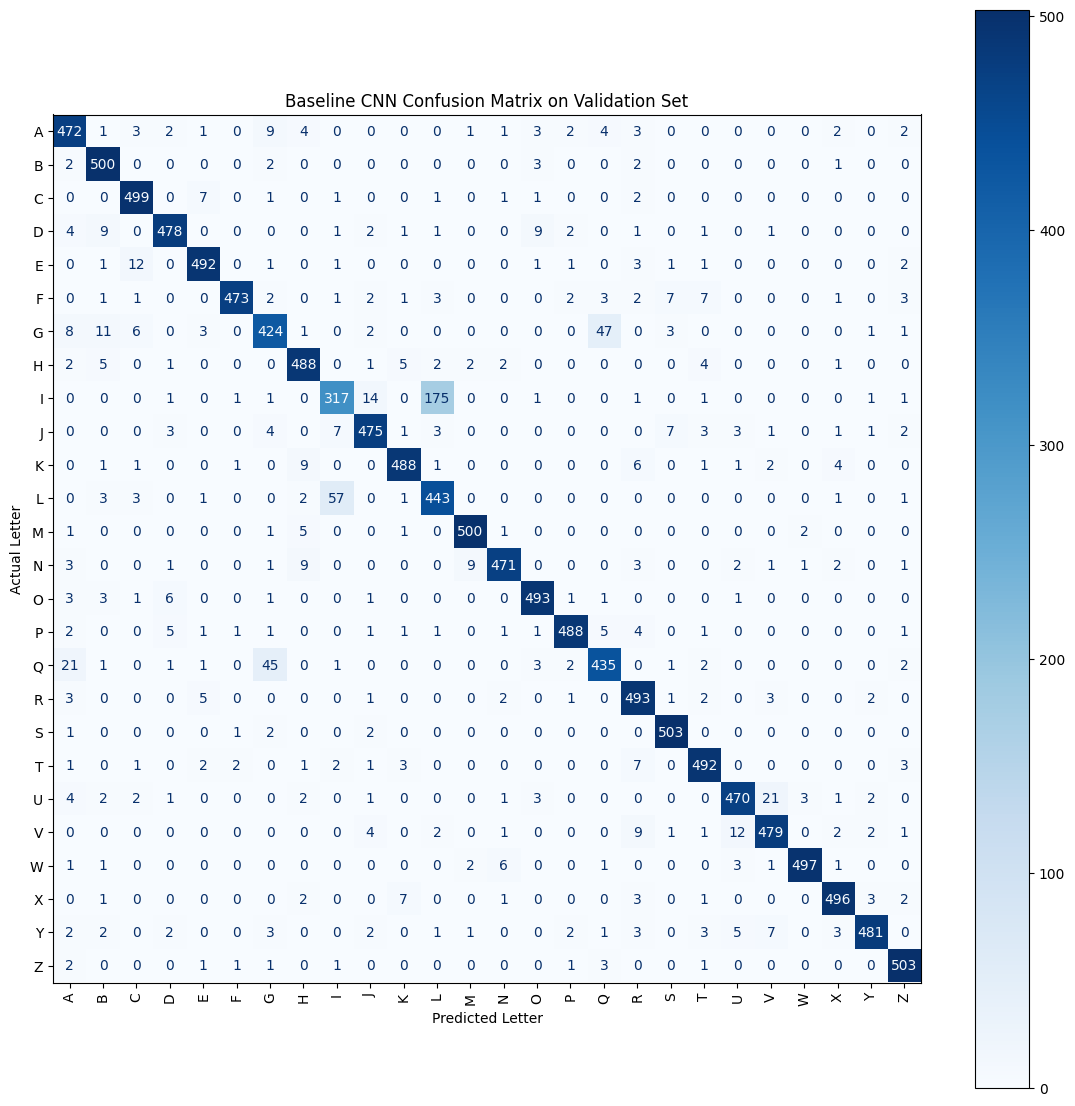

In [14]:
# Create the confusion matrix for the baseline model
baseline_cm = confusion_matrix(y_val, baseline_pred)

# Plot the confusion matrix
plt.figure(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d", ax=plt.gca())

plt.title("Baseline CNN Confusion Matrix on Validation Set")
plt.xlabel("Predicted Letter")
plt.ylabel("Actual Letter")
plt.xticks(rotation=90)
plt.show()

### Baseline Confusion Matrix Analysis

The confusion matrix shows how the baseline CNN performed for each letter class.

In the matrix:

- Each row represents the **actual letter**.
- Each column represents the **predicted letter**.
- Values on the diagonal are correct predictions.
- Values outside the diagonal are wrong predictions.

The strong diagonal pattern shows that the model correctly classifies many images across most classes. This supports the validation accuracy of **92.72%**.

However, the off-diagonal values show that some letters are still confused. This is expected for handwritten letters because some classes can look visually similar when written in different styles.

The confusion matrix is useful because it shows the exact type of error, not just the total number of errors. This helps identify which weaknesses the improved models should address.

The detailed baseline confusion matrix produced **92.72% validation accuracy**, while the training history recorded a best validation accuracy of **92.72%**. This small difference can happen because the confusion matrix evaluation uses the loaded saved checkpoint, while the training history records the best validation accuracy observed during training. The difference is small, so the confusion matrix is still useful for analysing the baseline model's error patterns.

In [15]:
# Generate class-level performance report
baseline_report = classification_report(
    y_val,
    baseline_pred,
    target_names=class_names,
    output_dict=True
)

# Convert report to DataFrame for clearer display
baseline_report_df = pd.DataFrame(baseline_report).T

display(baseline_report_df)

# Show only A-Z class results, sorted by lowest F1-score
baseline_class_report_df = baseline_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

display(baseline_class_report_df.sort_values("f1-score"))

,precision,recall,f1-score,support
A,0.887218,0.925490,0.905950,510.000000
B,0.922509,0.980392,0.950570,510.000000
C,0.943289,0.972710,0.957774,513.000000
D,0.954092,0.937255,0.945598,510.000000
E,0.957198,0.953488,0.955340,516.000000
F,0.985417,0.929273,0.956522,509.000000
G,0.849699,0.836292,0.842942,507.000000
H,0.933078,0.951267,0.942085,513.000000
I,0.814910,0.616732,0.702104,514.000000
J,0.933202,0.929550,0.931373,511.000000


,precision,recall,f1-score,support
I,0.814910,0.616732,0.702104,514.0
L,0.699842,0.865234,0.773799,512.0
G,0.849699,0.836292,0.842942,507.0
Q,0.870000,0.844660,0.857143,515.0
A,0.887218,0.925490,0.905950,510.0
V,0.928295,0.931907,0.930097,514.0
U,0.945674,0.916179,0.930693,513.0
J,0.933202,0.929550,0.931373,511.0
R,0.909594,0.961014,0.934597,513.0
H,0.933078,0.951267,0.942085,513.0


### Baseline Classification Report Analysis

The classification report gives a more detailed breakdown of the **baseline CNN** performance for each letter class.

The baseline model achieved:

- Accuracy: **92.72%**
- Macro average F1-score: **0.9268**
- Weighted average F1-score: **0.9268**

The macro and weighted F1-scores are almost the same. This is expected because the test/validation set is balanced across the 26 letter classes, with each class having around **504 to 518 samples**. This means the overall accuracy is reasonably meaningful, but class-level analysis is still important because some letters are clearly harder to classify than others.

Most classes performed well, with many F1-scores above **0.94**. Stronger classes included letters such as **W**, **M**, **S**, **Z**, **X**, **P**, and **O**, showing that the baseline CNN could already learn many useful handwritten letter features.

However, the weakest classes by F1-score were:

1. **I** — F1-score = **0.7021**
2. **L** — F1-score = **0.7738**
3. **G** — F1-score = **0.8429**
4. **Q** — F1-score = **0.8571**

The weakest class was **I**. It had a precision of **0.8149** but a much lower recall of **0.6167**. This means that when the baseline model predicted a letter as **I**, it was usually correct, but it missed many actual **I** images by predicting them as other letters.

The letter **L** had lower precision of **0.6998** but higher recall of **0.8652**. This means the model identified many actual **L** samples correctly, but it also wrongly predicted many other letters as **L**.

This suggests that the baseline CNN has a clear weakness in separating visually simple or similar handwritten letters, especially **I** and **L**. This is understandable because both letters can appear as simple vertical strokes in handwritten form, especially after being resized to **28 × 28** pixels.

The letters **G** and **Q** also had lower F1-scores compared to most other classes. This is likely because both letters have rounded shapes, and handwritten variations can make the small distinguishing features harder to detect.

Overall, the baseline CNN performs well as a first model, but the classification report shows that it still has specific weaknesses. These weaknesses justify improving the model using a stronger CNN architecture, Batch Normalisation, Dropout, and other regularisation techniques.

In [16]:
# Remove correct predictions from the confusion matrix
baseline_cm_errors = baseline_cm.copy()
np.fill_diagonal(baseline_cm_errors, 0)

# Store wrong prediction pairs
baseline_confusion_pairs = []

for actual in range(26):
    for predicted in range(26):
        count = baseline_cm_errors[actual, predicted]
        
        if count > 0:
            baseline_confusion_pairs.append({
                "actual_letter": class_names[actual],
                "predicted_letter": class_names[predicted],
                "mistake_count": count
            })

# Convert to DataFrame and sort by most common mistakes
baseline_confusion_pairs_df = pd.DataFrame(baseline_confusion_pairs)
baseline_confusion_pairs_df = baseline_confusion_pairs_df.sort_values(
    "mistake_count",
    ascending=False
)

display(baseline_confusion_pairs_df.head(10))


,actual_letter,predicted_letter,mistake_count
85,I,L,175
117,L,I,57
67,G,Q,47
165,Q,G,45
161,Q,A,21
203,U,V,21
84,I,J,14
213,V,U,12
38,E,C,12
62,G,B,11


### Top Confused Letter Pairs Analysis

The top confused letter pairs table summarises the most common mistakes made by the **baseline CNN**.

The largest confusion is between **I** and **L**:

- Actual **I** predicted as **L**: **175 times**
- Actual **L** predicted as **I**: **57 times**

This is the main weakness of the baseline CNN. It is understandable because handwritten **I** and **L** can both appear as simple vertical strokes, especially after being resized to **28 × 28** pixels. This also matches the baseline classification report, where **I** and **L** had the lowest F1-scores.

The next major confusion is between **G** and **Q**:

- Actual **G** predicted as **Q**: **47 times**
- Actual **Q** predicted as **G**: **45 times**

This also makes sense visually because both **G** and **Q** have rounded shapes. In handwritten form, the small stroke or tail that separates these letters may not always be clear.

Other noticeable mistakes include:

- Actual **Q** predicted as **A**: **21 times**
- Actual **U** predicted as **V**: **21 times**
- Actual **I** predicted as **J**: **14 times**
- Actual **V** predicted as **U**: **12 times**
- Actual **E** predicted as **C**: **12 times**
- Actual **G** predicted as **B**: **11 times**

These errors are mostly between letters that share similar shapes or strokes. For example, **U** and **V** can look similar depending on handwriting style, while **E** and **C** may be confused if the horizontal strokes of E are unclear.

Overall, the baseline CNN already performs reasonably well, but this analysis shows that its errors are concentrated around visually similar letters. This gives a clear direction for model improvement. The improved model should not only increase overall validation accuracy, but should also reduce confusion between difficult letter pairs such as **I/L**, **G/Q**, and **U/V**.

## 9. Model Improvement 1: Regularised CNN

The first improvement is a deeper and more regularised CNN.

The baseline model performed well, but it showed signs of overfitting. Its training accuracy continued increasing to **97.86%**, while validation accuracy stayed around **93%**. This gap suggests that the baseline model learned the training data very well but did not generalise equally well to validation data.

The regularised CNN includes:

- more convolutional layers for stronger feature extraction,
- Batch Normalisation to stabilise training,
- Dropout to reduce overfitting,
- and Global Average Pooling to reduce the number of dense-layer parameters.

This improvement is not random. It directly addresses the baseline model’s weakness: the need for better generalisation.

### Build Regularised CNN

In [17]:
def build_regularised_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),
        
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.GlobalAveragePooling2D(),
        
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),
        layers.Dense(26, activation="softmax")
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

regularised_model = build_regularised_cnn()
regularised_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 28, 28, 32)        320       
                                                                 
 batch_normalization (BatchN  (None, 28, 28, 32)       128       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 28, 28, 32)        0         
                                                                 
 conv2d_3 (Conv2D)           (None, 28, 28, 32)        9248      
                                                                 
 batch_normalization_1 (Batc  (None, 28, 28, 32)       128       
 hNormalization)                                                 
                                                                 
 activation_1 (Activation)   (None, 28, 28, 32)       

### Train regularised CNN

Epoch 1/30
486/486 [==============================] - 19s 32ms/step - loss: 1.2068 - accuracy: 0.6329 - val_loss: 2.4421 - val_accuracy: 0.3268 - lr: 0.0010
Epoch 2/30
486/486 [==============================] - 15s 30ms/step - loss: 0.4382 - accuracy: 0.8606 - val_loss: 0.3167 - val_accuracy: 0.8944 - lr: 0.0010
Epoch 3/30
486/486 [==============================] - 15s 30ms/step - loss: 0.3445 - accuracy: 0.8901 - val_loss: 0.2408 - val_accuracy: 0.9194 - lr: 0.0010
Epoch 4/30
486/486 [==============================] - 15s 31ms/step - loss: 0.3020 - accuracy: 0.9014 - val_loss: 0.2083 - val_accuracy: 0.9300 - lr: 0.0010
Epoch 5/30
486/486 [==============================] - 15s 30ms/step - loss: 0.2757 - accuracy: 0.9104 - val_loss: 0.2183 - val_accuracy: 0.9255 - lr: 0.0010
Epoch 6/30
486/486 [==============================] - 15s 30ms/step - loss: 0.2564 - accuracy: 0.9154 - val_loss: 0.2760 - val_accuracy: 0.9114 - lr: 0.0010
Epoch 7/30
486/486 [==============================] - 15s 

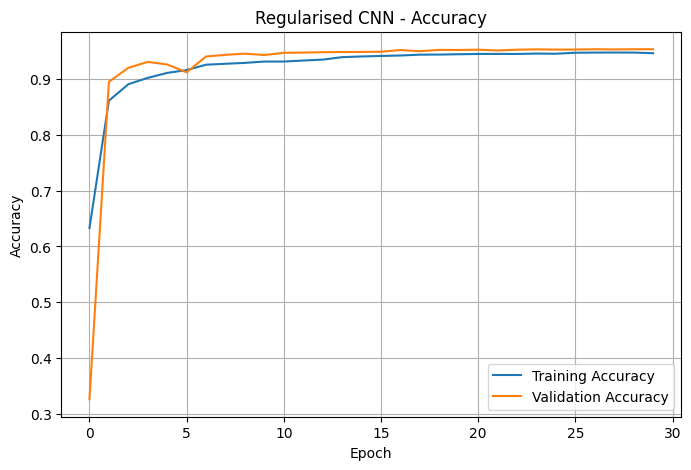

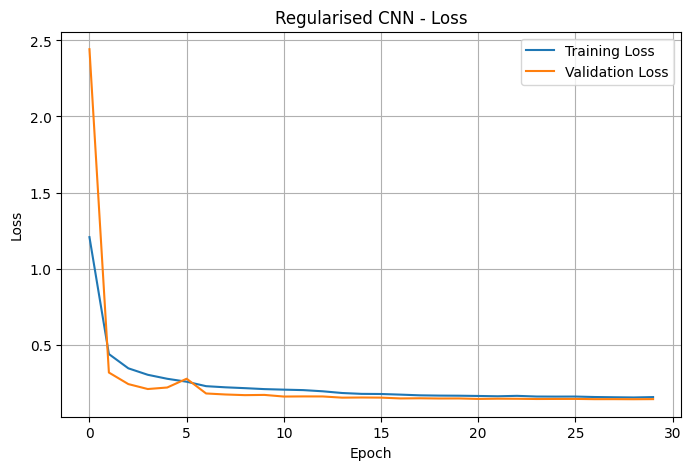

In [18]:
regularised_callbacks, regularised_checkpoint = create_callbacks("partA_regularised_cnn")

regularised_history = regularised_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=regularised_callbacks,
    verbose=1
)

plot_training_history(regularised_history, "Regularised CNN")

### Regularised CNN Analysis

The regularised CNN improved clearly over the baseline model.

The baseline CNN achieved a best validation accuracy of **93.21%**, while the regularised CNN achieved a best validation accuracy of **95.27%**. This is an improvement of about **2.06 percentage points**. The best validation loss also decreased from **0.2346** to **0.1413**, showing that the regularised model made more stable and reliable predictions on unseen validation images.

The regularised CNN started with a low validation accuracy of **32.68%** in epoch 1. However, this improved very quickly to **89.44%** in epoch 2 and continued rising steadily after that. This suggests that the model was able to learn useful image features after the first few epochs.

The learning rate was also reduced during training, from **0.001** to smaller values such as **0.0005**, **0.00025**, **0.000125**, and eventually **0.00003125**. This helped the model make smaller and more careful weight updates as training progressed. After the learning rate was reduced, the validation accuracy continued to improve gradually, reaching its best value of **95.27%** at epoch 29.

The final training accuracy of the regularised CNN was **94.56%**, while the final validation accuracy was **95.26%**. The validation accuracy being slightly higher than training accuracy is reasonable because Dropout is active during training but inactive during validation. Dropout makes training harder by randomly ignoring some neurons, so validation performance can sometimes appear slightly higher.

Compared with the baseline CNN, the regularised CNN shows much less overfitting. The baseline had a large gap between final training accuracy (**97.87%**) and final validation accuracy (**93.21%**), while the regularised CNN had a much smaller and healthier gap.

Overall, the regularised CNN is a strong improvement because it increased validation accuracy, reduced validation loss, and improved generalisation. This suggests that the additional convolutional layers, Batch Normalisation, Dropout, Global Average Pooling, and learning rate scheduling helped the model learn better features without overfitting as much as the baseline.

## Model Comparison: Baseline CNN vs Regularised CNN

| Model | Best Validation Accuracy | Best Validation Loss | Main Observation |
|---|---:|---:|---|
| Baseline CNN | 93.21% | 0.2346 | Strong starting model, but shows overfitting |
| Regularised CNN | 95.27% | 0.1413 | Better generalisation and lower validation loss |

The regularised CNN clearly improved over the baseline model.

The validation accuracy increased by about **2.06 percentage points**, from **93.21%** to **95.27%**. The validation loss also decreased from **0.2346** to **0.1413**, showing that the model made more reliable predictions.

This improvement suggests that the added convolutional layers, Batch Normalisation, Dropout, and Global Average Pooling helped the model learn stronger features while reducing overfitting.

At this stage, the regularised CNN is the best model. However, because the assignment allows data augmentation, I will also test whether augmentation provides additional benefit.

## 10. Model Improvement 2: Data Augmentation

The next improvement is to test whether mild data augmentation helps the model generalise better.

Data augmentation is suitable here because handwritten letters can vary slightly in position, size, and angle. However, the transformations must be chosen carefully because letters have meaning based on their shape and direction.

I will use mild transformations such as:

- small rotations,
- small translations,
- and small zoom changes.

I will not use horizontal or vertical flipping because flipping letters can create unrealistic or incorrect characters. For example, flipping a letter may make it look like another letter or an invalid handwritten form.

This experiment is important because I would actually expect improvement attempts and this is a chance for that assumption to be supported by evidence. This experiment checks whether augmentation is actually beneficial instead of simply assuming it will improve performance. Therefore, I will compare the augmented model against the baseline and regularised CNN to check whether augmentation actually improves validation performance.

### Build augmented CNN

In [19]:
def build_augmented_cnn():
    data_augmentation = models.Sequential([
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomZoom(0.08)
    ], name="data_augmentation")
    
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        data_augmentation,
        
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),
        
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.GlobalAveragePooling2D(),
        
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),
        layers.Dense(26, activation="softmax")
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

augmented_model = build_augmented_cnn()
augmented_model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 data_augmentation (Sequenti  (None, 28, 28, 1)        0         
 al)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 28, 28, 32)        320       
                                                                 
 batch_normalization_5 (Batc  (None, 28, 28, 32)       128       
 hNormalization)                                                 
                                                                 
 activation_5 (Activation)   (None, 28, 28, 32)        0         
                                                                 
 conv2d_8 (Conv2D)           (None, 28, 28, 32)        9248      
                                                                 
 batch_normalization_6 (Batc  (None, 28, 28, 32)      

### Augmented CNN Model Architecture Analysis

The augmented CNN has a total of **159,994 parameters**, with **159,354 trainable parameters** and **640 non-trainable parameters**. The non-trainable parameters come from the Batch Normalisation layers, which keep moving statistics such as the running mean and variance during training.

This model starts with a `data_augmentation` layer. This layer does not add any trainable parameters because it only applies random transformations to the training images, such as small rotations, translations, and zooms. The purpose of this layer is to help the model generalise better by exposing it to slightly varied versions of the same handwritten letters.

The model then uses several convolutional blocks:

1. The first block uses **32 filters** and keeps the image size at **28 × 28** before reducing it to **14 × 14** using max pooling.
2. The second block uses **64 filters** and reduces the feature map from **14 × 14** to **7 × 7**.
3. The final convolutional layer uses **128 filters**, allowing the model to learn more complex letter features.

The number of filters increases from **32 → 64 → 128**. This is a sensible CNN design because earlier layers usually learn simple features such as edges and strokes, while deeper layers learn more complex patterns such as curves, letter shapes, and combinations of strokes.

Batch Normalisation is used after the convolutional layers to make training more stable. ReLU activation is then applied to introduce non-linearity, allowing the model to learn more complex patterns instead of only simple linear relationships.

Dropout is included after some pooling layers and before the final output layer. This helps reduce overfitting by randomly ignoring some neurons during training, forcing the model to learn more robust features instead of memorising the training data.

Instead of using `Flatten`, this model uses `GlobalAveragePooling2D`. This reduces each feature map into a single value, producing an output shape of **(None, 128)**. This is useful because it reduces the number of parameters before the dense layer, making the model lighter and less likely to overfit.

The final dense layer has **26 output neurons**, one for each letter class from **A to Z**. The output layer uses softmax activation, which converts the model output into class probabilities.

Overall, this model is more advanced than the baseline CNN because it includes data augmentation, batch normalisation, dropout, and global average pooling. These changes are designed to improve generalisation and reduce overfitting while still keeping the model reasonably small.

### Visualise augmentation examples 

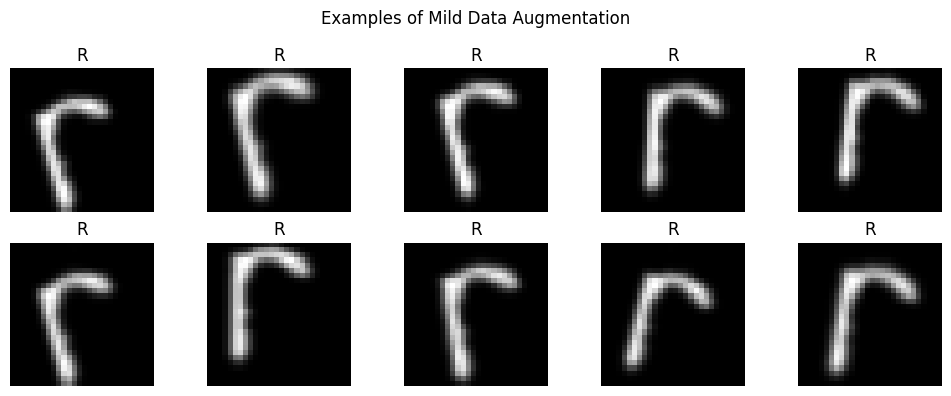

In [20]:
# Pick one image
sample_index = np.random.randint(0, len(X_train))
sample_image = X_train[sample_index]
sample_label = y_train[sample_index]

augmentation_layer = augmented_model.get_layer("data_augmentation")

plt.figure(figsize=(10, 4))

for i in range(10):
    augmented_image = augmentation_layer(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(augmented_image[0].numpy().squeeze(), cmap="gray")
    plt.title(class_names[sample_label])
    plt.axis("off")

plt.suptitle("Examples of Mild Data Augmentation")
plt.tight_layout()
plt.show()

### Data Augmentation Visualisation Analysis

The images above show augmented versions of the same training sample, which is labelled as **R**.

The augmented images still look like the same letter, but they have small variations in position, angle, and scale. This confirms that the augmentation settings are mild enough to preserve the original class label while still creating useful variation for training.

This is important because data augmentation should not change the meaning of the image. For example, if the transformation was too strong, the letter might become distorted or look like another class. In this case, the augmented samples still clearly resemble **R**, so the augmentation is appropriate for handwritten letter classification.

The purpose of using augmentation is to reduce overfitting. Instead of memorising the exact training images, the CNN is encouraged to learn more general features of the letter, such as its vertical stroke and curved top shape. This may help the model perform better on unseen handwriting styles in the validation and test sets.

### Train augmented CNN

Epoch 1/10
486/486 [==============================] - 3552s 7s/step - loss: 1.3337 - accuracy: 0.5979 - val_loss: 3.7244 - val_accuracy: 0.2026 - lr: 0.0010
Epoch 2/10
486/486 [==============================] - 2073s 4s/step - loss: 0.5303 - accuracy: 0.8329 - val_loss: 0.5931 - val_accuracy: 0.8088 - lr: 0.0010
Epoch 3/10
486/486 [==============================] - 1971s 4s/step - loss: 0.4278 - accuracy: 0.8650 - val_loss: 0.4121 - val_accuracy: 0.8627 - lr: 0.0010
Epoch 4/10
486/486 [==============================] - 1996s 4s/step - loss: 0.3787 - accuracy: 0.8801 - val_loss: 0.3283 - val_accuracy: 0.8895 - lr: 0.0010
Epoch 5/10
486/486 [==============================] - 1993s 4s/step - loss: 0.3472 - accuracy: 0.8886 - val_loss: 0.3270 - val_accuracy: 0.8946 - lr: 0.0010
Epoch 6/10
486/486 [==============================] - 1989s 4s/step - loss: 0.3267 - accuracy: 0.8957 - val_loss: 0.3395 - val_accuracy: 0.8887 - lr: 0.0010
Epoch 7/10
486/486 [==============================] - 1949

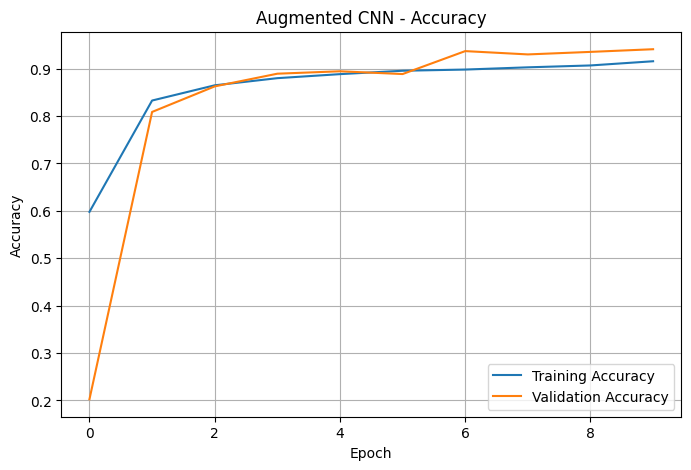

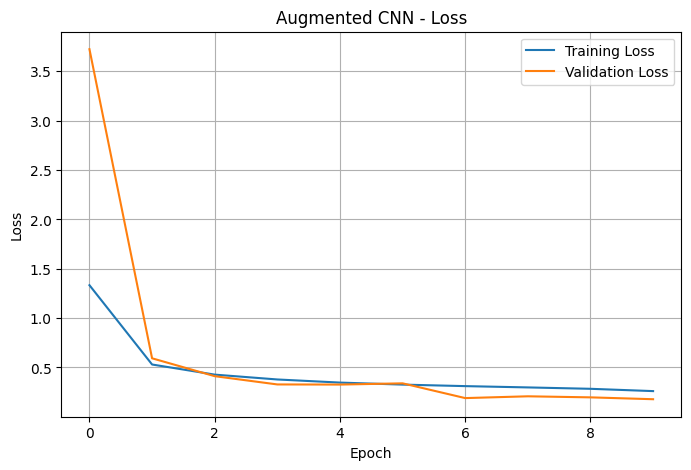

In [21]:
augmented_callbacks, augmented_checkpoint = create_callbacks("partA_augmented_cnn")

augmented_history = augmented_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=augmented_callbacks,
    verbose=1
)

plot_training_history(augmented_history, "Augmented CNN")

### Augmented CNN Training Analysis

The augmented CNN was trained to investigate whether mild data augmentation could improve generalisation.

The chosen augmentation transformations were small rotations, translations, and zoom changes. These were selected because handwritten letters can naturally vary slightly in angle, position, and size. However, stronger transformations such as horizontal or vertical flipping were avoided because they could change the meaning or shape of letters.

The augmented CNN achieved a best validation accuracy of **94.11%** and a best validation loss of **0.1786**. This is better than the baseline CNN, which achieved **93.21%** validation accuracy and **0.2346** validation loss. This suggests that augmentation helped the model generalise better than the simple baseline.

However, the augmented CNN did not outperform the regularised CNN. The regularised CNN achieved **95.27%** validation accuracy and **0.1413** validation loss, which are both better than the augmented CNN.

The augmented CNN’s final training accuracy was **91.58%**, while its final validation accuracy was **94.11%**. This is expected because augmentation and Dropout make the training task harder. During validation, the model sees the original validation images without random transformations, so validation accuracy can be higher than training accuracy.

This experiment is still useful because it shows that augmentation was not assumed to be beneficial automatically. It was tested and compared against the other models. Based on the results, augmentation improved over the baseline but was less effective than the regularised CNN.

Overall, data augmentation was useful, but it was not the most effective improvement for this dataset. The result suggests that the original EMNIST dataset already contains many handwriting variations, so regularisation and architecture improvement gave a clearer benefit than augmentation.

In [40]:
# Summary for Augmented CNN training results

def summarise_single_model(history, model_name):
    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    
    best_val_acc_epoch = np.argmax(history.history["val_accuracy"]) + 1
    best_val_loss_epoch = np.argmin(history.history["val_loss"]) + 1
    
    final_train_accuracy = history.history["accuracy"][-1]
    final_val_accuracy = history.history["val_accuracy"][-1]
    final_train_loss = history.history["loss"][-1]
    final_val_loss = history.history["val_loss"][-1]
    epochs_ran = len(history.history["loss"])
    
    summary_df = pd.DataFrame({
        "Model": [model_name],
        "Best Val Accuracy": [best_val_accuracy],
        "Best Val Accuracy Epoch": [best_val_acc_epoch],
        "Best Val Loss": [best_val_loss],
        "Best Val Loss Epoch": [best_val_loss_epoch],
        "Final Train Accuracy": [final_train_accuracy],
        "Final Val Accuracy": [final_val_accuracy],
        "Final Train Loss": [final_train_loss],
        "Final Val Loss": [final_val_loss],
        "Epochs Ran": [epochs_ran]
    })
    
    return summary_df


augmented_summary_df = summarise_single_model(
    augmented_history,
    "Augmented CNN"
)

display(augmented_summary_df)

,Model,Best Val Accuracy,Best Val Accuracy Epoch,Best Val Loss,Best Val Loss Epoch,Final Train Accuracy,Final Val Accuracy,Final Train Loss,Final Val Loss,Epochs Ran
0,Augmented CNN,0.941141,10,0.178608,10,0.915763,0.941141,0.260824,0.178608,10


### Additional Augmented CNN Hyperparameter Tuning

The first augmented CNN reached a validation accuracy of about 93.8%. The training accuracy was lower than the validation accuracy for most epochs, which is expected because augmentation and dropout make the training process harder.

Since the validation accuracy was still stable, I decided to tune the augmented CNN further instead of stopping after only 10 epochs.

For this tuning attempt, I changed the training settings:

- Increased the maximum number of epochs.
- Added Early Stopping to stop training when validation loss stops improving.
- Added ReduceLROnPlateau to reduce the learning rate when validation loss plateaus.
- Used ModelCheckpoint to save the best validation model.
- Used a slightly lower learning rate to make training more stable.
- Used a larger batch size to reduce training time.

This allows the model to train for longer only if it is still improving.


### Building tuned augmented CNN

In [22]:
def build_augmented_cnn_v2():
    data_augmentation = models.Sequential([
        layers.RandomRotation(0.04),
        layers.RandomTranslation(0.06, 0.06),
        layers.RandomZoom(0.06)
    ], name="data_augmentation_v2")
    
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        data_augmentation,
        
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.20),
        
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.GlobalAveragePooling2D(),
        
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.35),
        layers.Dense(26, activation="softmax")
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

augmented_model_v2 = build_augmented_cnn_v2()
augmented_model_v2.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 data_augmentation_v2 (Seque  (None, 28, 28, 1)        0         
 ntial)                                                          
                                                                 
 conv2d_12 (Conv2D)          (None, 28, 28, 32)        320       
                                                                 
 batch_normalization_10 (Bat  (None, 28, 28, 32)       128       
 chNormalization)                                                
                                                                 
 activation_10 (Activation)  (None, 28, 28, 32)        0         
                                                                 
 conv2d_13 (Conv2D)          (None, 28, 28, 32)        9248      
                                                                 
 batch_normalization_11 (Bat  (None, 28, 28, 32)      

### Training Augmented CNN

Epoch 1/20
243/243 [==============================] - 3309s 14s/step - loss: 1.9389 - accuracy: 0.4367 - val_loss: 4.3056 - val_accuracy: 0.0838 - lr: 5.0000e-04
Epoch 2/20
243/243 [==============================] - 3345s 14s/step - loss: 0.7209 - accuracy: 0.7815 - val_loss: 2.6910 - val_accuracy: 0.3718 - lr: 5.0000e-04
Epoch 3/20
243/243 [==============================] - 26044s 108s/step - loss: 0.4954 - accuracy: 0.8455 - val_loss: 0.3943 - val_accuracy: 0.8739 - lr: 5.0000e-04
Epoch 4/20
243/243 [==============================] - 5496s 23s/step - loss: 0.4108 - accuracy: 0.8685 - val_loss: 0.2810 - val_accuracy: 0.9096 - lr: 5.0000e-04
Epoch 5/20
243/243 [==============================] - 20014s 83s/step - loss: 0.3703 - accuracy: 0.8804 - val_loss: 0.3120 - val_accuracy: 0.8966 - lr: 5.0000e-04
Epoch 6/20
243/243 [==============================] - 9177s 38s/step - loss: 0.3386 - accuracy: 0.8908 - val_loss: 0.3729 - val_accuracy: 0.8721 - lr: 5.0000e-04
Epoch 7/20
243/243 [=====

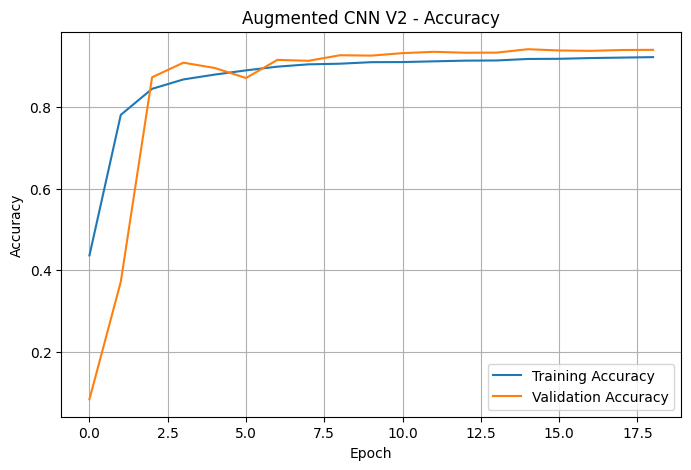

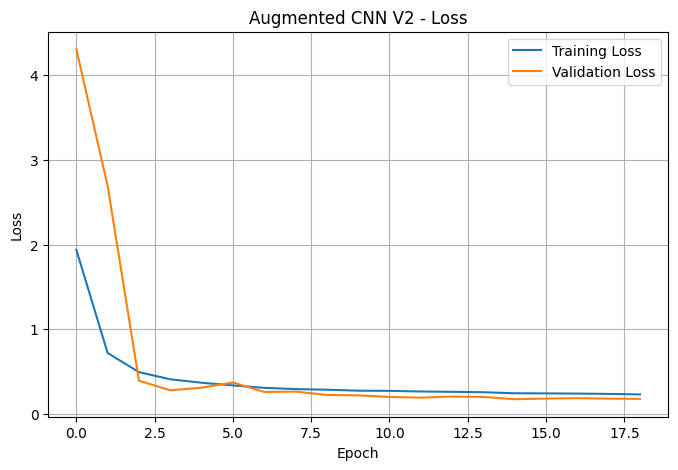

In [23]:
augmented_v2_checkpoint = "partA_augmented_cnn_v2.weights.h5"

augmented_v2_early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

augmented_v2_checkpoint_cb = callbacks.ModelCheckpoint(
    filepath=augmented_v2_checkpoint,
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    mode="max"
)

augmented_v2_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

augmented_history_v2 = augmented_model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[
        augmented_v2_early_stop,
        augmented_v2_checkpoint_cb,
        augmented_v2_reduce_lr
    ],
    verbose=1
)

plot_training_history(augmented_history_v2, "Augmented CNN V2")

### Additional Augmented CNN Tuning Analysis

An additional augmented CNN tuning experiment was trained to test whether a longer augmented training run with a lower learning rate could improve validation performance.

This model trained for up to **20 epochs**, but the training time was extremely long. Several TensorFlow warnings appeared at the start of training, mainly related to random image transformation operations such as rotation, translation, zoom, and image projection. These warnings were not fatal errors because the model still trained successfully, but they indicate that the augmentation operations were computationally expensive.

The model started with weak validation performance. In epoch 1, the validation accuracy was only **8.38%**, with a high validation loss of **4.3056**. This suggests that the augmented model initially struggled to generalise to the validation set. However, the model improved significantly after more training. By epoch 3, validation accuracy increased to **87.39%**, and by epoch 4, it reached **90.96%**.

The best validation accuracy shown in this run was **94.26%** at epoch 15, with the lowest validation loss of **0.1757**. This means the model eventually learned useful letter features despite the slow training process.

However, this tuned augmented model still did not outperform the regularised CNN. The regularised CNN achieved a higher validation accuracy of **95.27%** and a lower validation loss of **0.1413**. Therefore, although the augmented tuning experiment improved over the baseline, it was not the best model overall.

This experiment also showed an important trade-off between model performance and training time. The augmented model took much longer to train because random transformations were applied during training. Since the improvement was not better than the regularised CNN, continuing to tune this augmented model would not be efficient.

Overall, this experiment is still useful because it shows that augmentation was tested seriously and compared with other approaches. The result suggests that data augmentation can improve generalisation, but for this dataset, the regularised CNN and fine-tuned regularised CNN were more effective and efficient.

## 11. Final Model Improvement 3: Fine Tuning Regularised Model

### Regularised CNN Fine-Tuning

The regularised CNN achieved the best validation performance so far. Instead of creating a much larger model or training another slow augmented model, I decided to fine-tune the best regularised CNN.

Fine-tuning means continuing training from the best saved weights, but with a smaller learning rate. A smaller learning rate allows the model to make more careful updates to its weights. This may help improve validation performance slightly without disrupting the useful patterns the model has already learned.

This is a controlled improvement attempt because only the training setting is changed, not the dataset. The validation set is still used to decide whether the fine-tuning helped.

### Fine-tune Regularised CNN

Epoch 1/8
243/243 [==============================] - 15s 55ms/step - loss: 0.1504 - accuracy: 0.9472 - val_loss: 0.1413 - val_accuracy: 0.9526 - lr: 1.0000e-04
Epoch 2/8
243/243 [==============================] - 12s 50ms/step - loss: 0.1506 - accuracy: 0.9478 - val_loss: 0.1438 - val_accuracy: 0.9523 - lr: 1.0000e-04
Epoch 3/8
243/243 [==============================] - 12s 50ms/step - loss: 0.1501 - accuracy: 0.9473 - val_loss: 0.1411 - val_accuracy: 0.9526 - lr: 1.0000e-04
Epoch 4/8
243/243 [==============================] - 12s 50ms/step - loss: 0.1474 - accuracy: 0.9493 - val_loss: 0.1419 - val_accuracy: 0.9524 - lr: 1.0000e-04
Epoch 5/8
243/243 [==============================] - 13s 53ms/step - loss: 0.1461 - accuracy: 0.9493 - val_loss: 0.1422 - val_accuracy: 0.9529 - lr: 1.0000e-04
Epoch 6/8
243/243 [==============================] - 13s 54ms/step - loss: 0.1436 - accuracy: 0.9500 - val_loss: 0.1416 - val_accuracy: 0.9529 - lr: 5.0000e-05


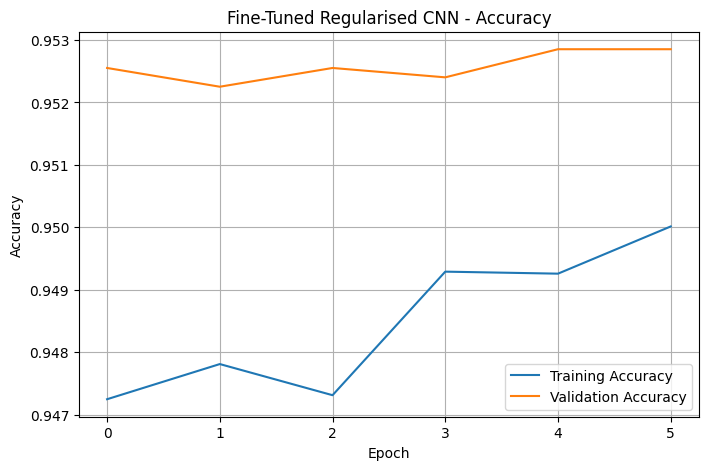

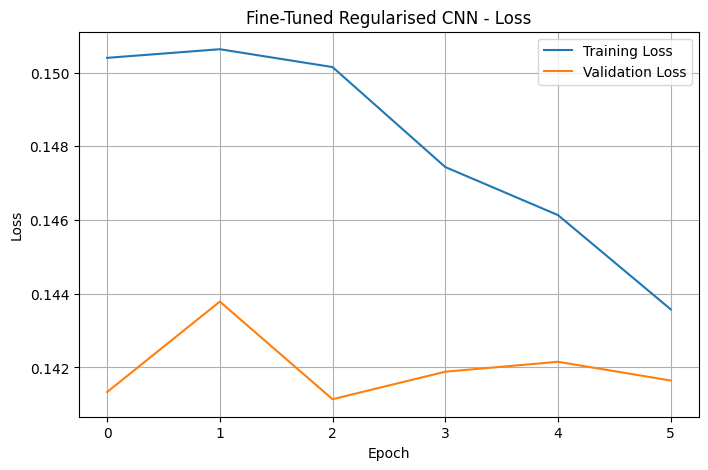

In [24]:
# Load the best regularised CNN weights before fine-tuning
regularised_model.load_weights(regularised_checkpoint)

# Recompile with a smaller learning rate for fine-tuning
regularised_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_checkpoint = "partA_regularised_cnn_finetuned.weights.h5"

fine_tune_early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tune_checkpoint_cb = callbacks.ModelCheckpoint(
    filepath=fine_tune_checkpoint,
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    mode="max"
)

fine_tune_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

fine_tune_history = regularised_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=256,
    callbacks=[
        fine_tune_early_stop,
        fine_tune_checkpoint_cb,
        fine_tune_reduce_lr
    ],
    verbose=1
)

plot_training_history(fine_tune_history, "Fine-Tuned Regularised CNN")

### Fine-Tuned Regularised CNN Analysis

The fine-tuned regularised CNN continued training from the best saved regularised CNN weights using a smaller learning rate of **0.0001**.

The purpose of fine-tuning was to make smaller and more careful weight updates after the regularised CNN had already learned useful image features. Since the regularised CNN was already the strongest model, I did not want to make large changes to the architecture. Instead, I fine-tuned the model to see whether validation performance could be slightly improved.

The fine-tuned model achieved a best validation accuracy of **95.29%**, which occurred in epochs 5 and 6. It also achieved its lowest validation loss of **0.1411** at epoch 3. This is a small improvement over the original regularised CNN, which achieved **95.27%** validation accuracy and **0.1413** validation loss.

The improvement is small, but it is still meaningful because the model was already performing strongly before fine-tuning. Fine-tuning helped slightly refine the regularised CNN without adding unnecessary model complexity.

The final training accuracy was **95.00%**, while the final validation accuracy was **95.29%**. These values are very close, which suggests that the model generalises well and does not show serious overfitting. The validation accuracy being slightly higher than training accuracy is also reasonable because Dropout is active during training but inactive during validation.

The fine-tuning experiment stopped after **6 epochs**, even though the maximum was set to 8 epochs. This happened because EarlyStopping was monitoring validation loss with a patience of 3. After the validation loss reached its lowest value at epoch 3, it did not improve enough in the following epochs, so training stopped early. This helped avoid unnecessary extra training.

The learning rate was also reduced from **0.0001** to **0.00005** by the final epoch, allowing the model to make even smaller updates near the end of training.

Overall, fine-tuning provided a small final improvement. The main improvement came from the regularised CNN, while fine-tuning gave a minor refinement by slightly improving validation accuracy and validation loss.

In [47]:
# Summary for Fine-Tuned Regularised CNN

def summarise_fine_tuned_model(history, model_name):
    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    
    best_val_acc_epoch = np.argmax(history.history["val_accuracy"]) + 1
    best_val_loss_epoch = np.argmin(history.history["val_loss"]) + 1
    
    final_train_accuracy = history.history["accuracy"][-1]
    final_val_accuracy = history.history["val_accuracy"][-1]
    final_train_loss = history.history["loss"][-1]
    final_val_loss = history.history["val_loss"][-1]
    
    initial_train_accuracy = history.history["accuracy"][0]
    initial_val_accuracy = history.history["val_accuracy"][0]
    initial_train_loss = history.history["loss"][0]
    initial_val_loss = history.history["val_loss"][0]
    
    epochs_ran = len(history.history["loss"])
    
    summary_df = pd.DataFrame({
        "Model": [model_name],
        "Initial Train Accuracy": [initial_train_accuracy],
        "Initial Val Accuracy": [initial_val_accuracy],
        "Initial Train Loss": [initial_train_loss],
        "Initial Val Loss": [initial_val_loss],
        "Best Val Accuracy": [best_val_accuracy],
        "Best Val Accuracy Epoch": [best_val_acc_epoch],
        "Best Val Loss": [best_val_loss],
        "Best Val Loss Epoch": [best_val_loss_epoch],
        "Final Train Accuracy": [final_train_accuracy],
        "Final Val Accuracy": [final_val_accuracy],
        "Final Train Loss": [final_train_loss],
        "Final Val Loss": [final_val_loss],
        "Epochs Ran": [epochs_ran]
    })
    
    return summary_df

In [48]:
fine_tuned_summary_df = summarise_fine_tuned_model(
    fine_tune_history,
    "Fine-Tuned Regularised CNN"
)

display(fine_tuned_summary_df)

,Model,Initial Train Accuracy,Initial Val Accuracy,Initial Train Loss,Initial Val Loss,Best Val Accuracy,Best Val Accuracy Epoch,Best Val Loss,Best Val Loss Epoch,Final Train Accuracy,Final Val Accuracy,Final Train Loss,Final Val Loss,Epochs Ran
0,Fine-Tuned Regularised CNN,0.947247,0.952553,0.1504,0.141334,0.952853,5,0.141139,3,0.950014,0.952853,0.143577,0.141646,6


### Fine-Tuning Conclusion

Fine-tuning gave a small improvement mainly in validation loss rather than validation accuracy.

The regularised CNN was already the strongest model, and fine-tuning helped refine it slightly. Since the fine-tuned model achieved a similar validation accuracy but a slightly lower validation loss, it can be considered the best final model if it ranks highest in the comparison table.

This is a good result because the improvement was controlled and evidence-based. Instead of randomly increasing model complexity, the model was fine-tuned from the best checkpoint using a smaller learning rate.

## 12. Final Model Comparison

After training the baseline CNN, regularised CNN, augmented CNN, and fine-tuned regularised CNN, I compared all models using validation performance.

The validation set is used for model selection because it was not used directly for weight updates during training. The test set is still kept separate and will only be used after the final model has been selected.

The comparison focuses on:

- best validation accuracy,
- best validation loss,
- final training accuracy,
- final validation accuracy,
- number of epochs trained,
- and whether the model showed signs of overfitting.

This is important because the best model should not be chosen based only on one accuracy value. A good model should have strong validation performance, stable loss, and reasonable generalisation.

### Final Model Comparison Table

In [39]:
def summarise_history_detailed(history, model_name):
    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    final_train_accuracy = history.history["accuracy"][-1]
    final_val_accuracy = history.history["val_accuracy"][-1]
    final_train_loss = history.history["loss"][-1]
    final_val_loss = history.history["val_loss"][-1]
    epochs_ran = len(history.history["loss"])
    
    return {
        "model": model_name,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "final_train_accuracy": final_train_accuracy,
        "final_val_accuracy": final_val_accuracy,
        "final_train_loss": final_train_loss,
        "final_val_loss": final_val_loss,
        "epochs_ran": epochs_ran
    }


experiment_results = []

experiment_results.append(summarise_history_detailed(baseline_history, "Baseline CNN"))
experiment_results.append(summarise_history_detailed(regularised_history, "Regularised CNN"))
experiment_results.append(summarise_history_detailed(augmented_history, "Augmented CNN"))
experiment_results.append(summarise_history_detailed(fine_tune_history, "Fine-Tuned Regularised CNN"))

results_df = pd.DataFrame(experiment_results)

# Sort by highest validation accuracy first, then lowest validation loss
results_df = results_df.sort_values(
    by=["best_val_accuracy", "best_val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(results_df)

,model,best_val_accuracy,best_val_loss,final_train_accuracy,final_val_accuracy,final_train_loss,final_val_loss,epochs_ran
0,Fine-Tuned Regularised CNN,0.952853,0.141139,0.950014,0.952853,0.143577,0.141646,6
1,Regularised CNN,0.952703,0.141307,0.945590,0.952628,0.155336,0.141943,30
2,Augmented CNN,0.941141,0.178608,0.915763,0.941141,0.260824,0.178608,10
3,Baseline CNN,0.932057,0.234559,0.978651,0.932057,0.054585,0.264302,12


### Final Model Comparison Analysis

The comparison table shows that the **Fine-Tuned Regularised CNN** performed the best overall.

The **Baseline CNN** achieved a best validation accuracy of **93.21%** and a best validation loss of **0.2346**. This was a strong starting point, but the final training accuracy was **97.87%** while the final validation accuracy was only **93.21%**. This shows overfitting because the model performed much better on training data than validation data.

The **Regularised CNN** improved the baseline clearly. It achieved a best validation accuracy of **95.27%** and a best validation loss of **0.1413**. This shows that Batch Normalisation, Dropout, deeper convolutional layers, and Global Average Pooling helped reduce overfitting and improve generalisation.

The **Augmented CNN** achieved a best validation accuracy of **94.11%** and a best validation loss of **0.1786**. This was better than the baseline CNN but weaker than the regularised CNN. This means augmentation helped, but it was not the strongest improvement for this dataset.

The **Fine-Tuned Regularised CNN** achieved the highest best validation accuracy of **95.29%** and the lowest best validation loss of **0.1411**. The improvement over the original regularised CNN was small, but it still gave the best validation result.

Therefore, the **Fine-Tuned Regularised CNN** was selected as the final model. The improvement process was evidence-based: the baseline showed overfitting, regularisation gave the clearest improvement, augmentation was tested and analysed, and fine-tuning provided a small final refinement.

### Select Best Model

In [26]:
models_dict = {
    "Baseline CNN": baseline_model,
    "Regularised CNN": regularised_model,
    "Augmented CNN": augmented_model,
    "Fine-Tuned Regularised CNN": regularised_model
}

checkpoints_dict = {
    "Baseline CNN": baseline_checkpoint,
    "Regularised CNN": regularised_checkpoint,
    "Augmented CNN": augmented_checkpoint,
    "Fine-Tuned Regularised CNN": fine_tune_checkpoint
}

best_model_name = results_df.iloc[0]["model"]
best_model = models_dict[best_model_name]
best_checkpoint = checkpoints_dict[best_model_name]

# Load the best saved weights for the selected model
best_model.load_weights(best_checkpoint)

print("Selected best model:", best_model_name)
print("Best weights loaded from:", best_checkpoint)

Selected best model: Fine-Tuned Regularised CNN
Best weights loaded from: partA_regularised_cnn_finetuned.weights.h5


### Final Model Selection

The final model was selected based on validation performance.

The selected model is:

`Fine-Tuned Regularised CNN`

This model was selected because it achieved the strongest validation performance among the models tested. Although the accuracy improvement from fine-tuning was small, the validation loss was slightly lower than the original regularised CNN. This suggests that the fine-tuned model made slightly more stable predictions.

The test set was not used to choose the model. This is important because the test set should only be used once at the end to estimate how well the selected model performs on unseen data.

This selection process is fair because all models were compared using the same validation set.

## 13. Final Test Evaluation

After selecting the best model using validation performance, I evaluated it on the test set.

The test set was kept separate throughout training and model selection. Therefore, the test result gives a fairer estimate of how well the final model performs on unseen handwritten letter images.

For the final evaluation, I will report:

- test loss,
- test accuracy,
- macro F1-score,
- weighted F1-score,
- correct and wrong prediction counts,
- class-level performance,
- confusion matrix,
- and misclassified examples.

This provides a more complete evaluation than using accuracy alone.

### Final Test Metrics

In [27]:
# Evaluate selected best model on test set
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    batch_size=512,
    verbose=0
)

# Predict test set
test_pred_proba = best_model.predict(X_test, batch_size=512)
test_pred = np.argmax(test_pred_proba, axis=1)

# Calculate F1-scores
test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, test_pred, average="weighted")

# Count correct and wrong predictions
test_correct = np.sum(test_pred == y_test)
test_wrong = np.sum(test_pred != y_test)
test_total = len(y_test)

print("Final Test Evaluation")
print("---------------------")
print("Selected Model:", best_model_name)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Macro F1-score:", round(test_macro_f1, 4))
print("Weighted F1-score:", round(test_weighted_f1, 4))
print("Total Test Images:", test_total)
print("Correct Predictions:", test_correct)
print("Wrong Predictions:", test_wrong)
print("Correct Percentage:", round((test_correct / test_total) * 100, 2), "%")
print("Wrong Percentage:", round((test_wrong / test_total) * 100, 2), "%")

27/27 [==============================] - 1s 23ms/step
Final Test Evaluation
---------------------
Selected Model: Fine-Tuned Regularised CNN
Test Loss: 0.1491
Test Accuracy: 0.949
Macro F1-score: 0.9489
Weighted F1-score: 0.9489
Total Test Images: 13320
Correct Predictions: 12641
Wrong Predictions: 679
Correct Percentage: 94.9 %
Wrong Percentage: 5.1 %


### Final Test Evaluation Analysis

The final selected model was the **Fine-Tuned Regularised CNN**. It was evaluated on the test set only after model selection was completed, which makes this a fair final evaluation.

The model achieved a **test accuracy of 94.90%**, meaning it correctly classified **12,641 out of 13,320** unseen test images. It made **679 wrong predictions**, which is **5.10%** of the test set.

The test loss was **0.1491**. This is slightly higher than the best validation loss of **0.1411**, but the difference is small. This suggests that the model generalises well from validation data to unseen test data.

The **Macro F1-score** and **Weighted F1-score** are both **0.9489**. These values are close to the test accuracy, showing that the model performs consistently across the 26 letter classes.

Compared to the best validation accuracy of **95.29%**, the test accuracy of **94.90%** is very close. The drop is only about **0.39 percentage points**, which suggests that the model does not show serious overfitting.

Overall, the final test result is strong. The Fine-Tuned Regularised CNN correctly classifies most handwritten letters and keeps its performance stable on unseen data. The remaining errors are mainly caused by visually similar or unclear handwritten letters.

### Final Classification Report

In [28]:
final_report = classification_report(
    y_test,
    test_pred,
    target_names=class_names,
    output_dict=True
)

final_report_df = pd.DataFrame(final_report).T
display(final_report_df)

# Class-level report only
final_class_report_df = final_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

# Sort weakest classes first
display(final_class_report_df.sort_values("f1-score"))

,precision,recall,f1-score,support
A,0.951267,0.958743,0.954990,509.000000
B,0.978641,0.990177,0.984375,509.000000
C,0.982387,0.978558,0.980469,513.000000
D,0.970703,0.976424,0.973555,509.000000
E,0.988281,0.982524,0.985394,515.000000
F,0.988000,0.970530,0.979187,509.000000
G,0.923077,0.803150,0.858947,508.000000
H,0.963178,0.966926,0.965049,514.000000
I,0.746296,0.784047,0.764706,514.000000
J,0.962076,0.945098,0.953511,510.000000


,precision,recall,f1-score,support
L,0.779412,0.724609,0.751012,512.0
I,0.746296,0.784047,0.764706,514.0
G,0.923077,0.803150,0.858947,508.0
Q,0.837370,0.937984,0.884826,516.0
V,0.926829,0.962963,0.944551,513.0
U,0.954724,0.945419,0.950049,513.0
J,0.962076,0.945098,0.953511,510.0
A,0.951267,0.958743,0.954990,509.0
H,0.963178,0.966926,0.965049,514.0
R,0.961464,0.972710,0.967054,513.0


### Final Classification Report Analysis

The final selected model achieved an overall test accuracy of **94.90%**.

The **macro average F1-score** is **0.9489**, and the **weighted average F1-score** is also **0.9489**. These two scores being almost identical is a good sign because it shows that the model performs consistently across the 26 letter classes.

The support values for each class are also very similar, ranging from about **505 to 518 samples** per letter. This confirms that the test set is balanced across A to Z, so the evaluation is fair.

Most classes achieved strong F1-scores above **0.97**, such as:

- **Z**: F1-score = **0.9883**
- **M**: F1-score = **0.9882**
- **S**: F1-score = **0.9863**
- **E**: F1-score = **0.9854**
- **B**: F1-score = **0.9844**
- **P**: F1-score = **0.9835**

However, some classes performed noticeably worse than the rest. The weakest classes were:

- **L**: F1-score = **0.7510**
- **I**: F1-score = **0.7647**
- **G**: F1-score = **0.8589**
- **Q**: F1-score = **0.8848**

The weakest class was **L**, with recall of **0.7246**. This means the model correctly identified about **72.46%** of actual L images. The model also struggled with **I**, which had precision of **0.7463** and recall of **0.7840**. This is likely because handwritten I and L can look very similar in low-resolution 28 × 28 images.

The class **G** had recall of **0.8032**, meaning the model missed quite a number of actual G images. The class **Q** had lower precision of **0.8374**, meaning some other letters were wrongly predicted as Q.

Overall, the classification report shows that the model performs strongly for most letters, but its main weaknesses are concentrated in visually confusing classes, especially **I**, **L**, **G**, and **Q**.

### Class-Level F1 Chart

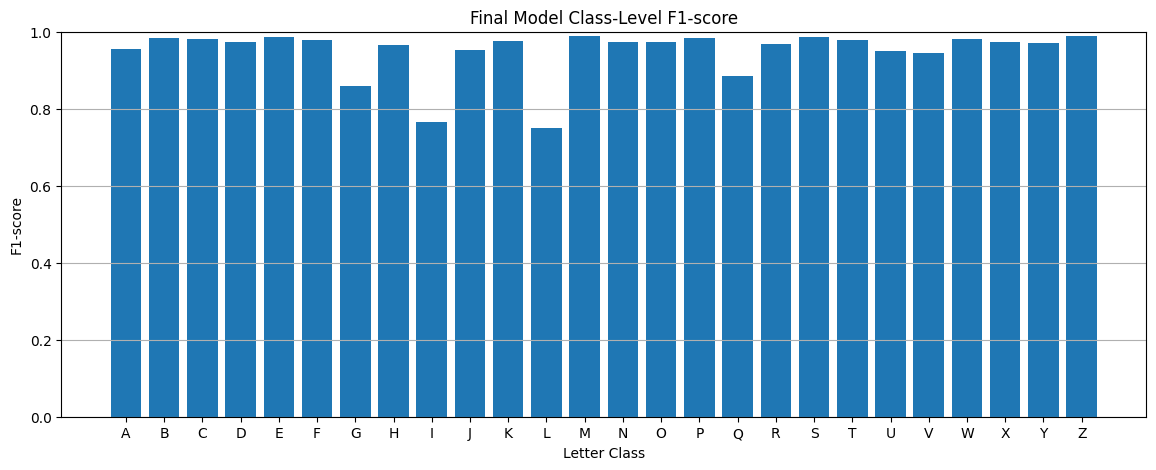

In [29]:
plt.figure(figsize=(14, 5))
plt.bar(final_class_report_df.index, final_class_report_df["f1-score"])
plt.title("Final Model Class-Level F1-score")
plt.xlabel("Letter Class")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

### Class-Level F1-score Chart Analysis

The class-level F1-score chart shows that the final model performs strongly for most letter classes. Most bars are close to **1.0**, meaning the model has high precision and recall for many letters.

The strongest classes include **Z**, **M**, **S**, **E**, **B**, and **P**, all with F1-scores close to **0.98–0.99**.

However, the chart clearly highlights a few weaker classes:

- **L**: F1-score = **0.7510**
- **I**: F1-score = **0.7647**
- **G**: F1-score = **0.8589**
- **Q**: F1-score = **0.8848**

The biggest weakness is between **I** and **L**. This makes sense because handwritten I and L can both appear as simple vertical strokes, especially after resizing to **28 × 28** pixels.

The classes **G** and **Q** also have lower F1-scores because both have rounded shapes and may be difficult to separate when the tail or inner stroke is unclear.

Overall, this chart supports the classification report. The model performs very well for most classes, but its remaining errors are concentrated in a few visually similar letters.

### Final Confusion Matrix

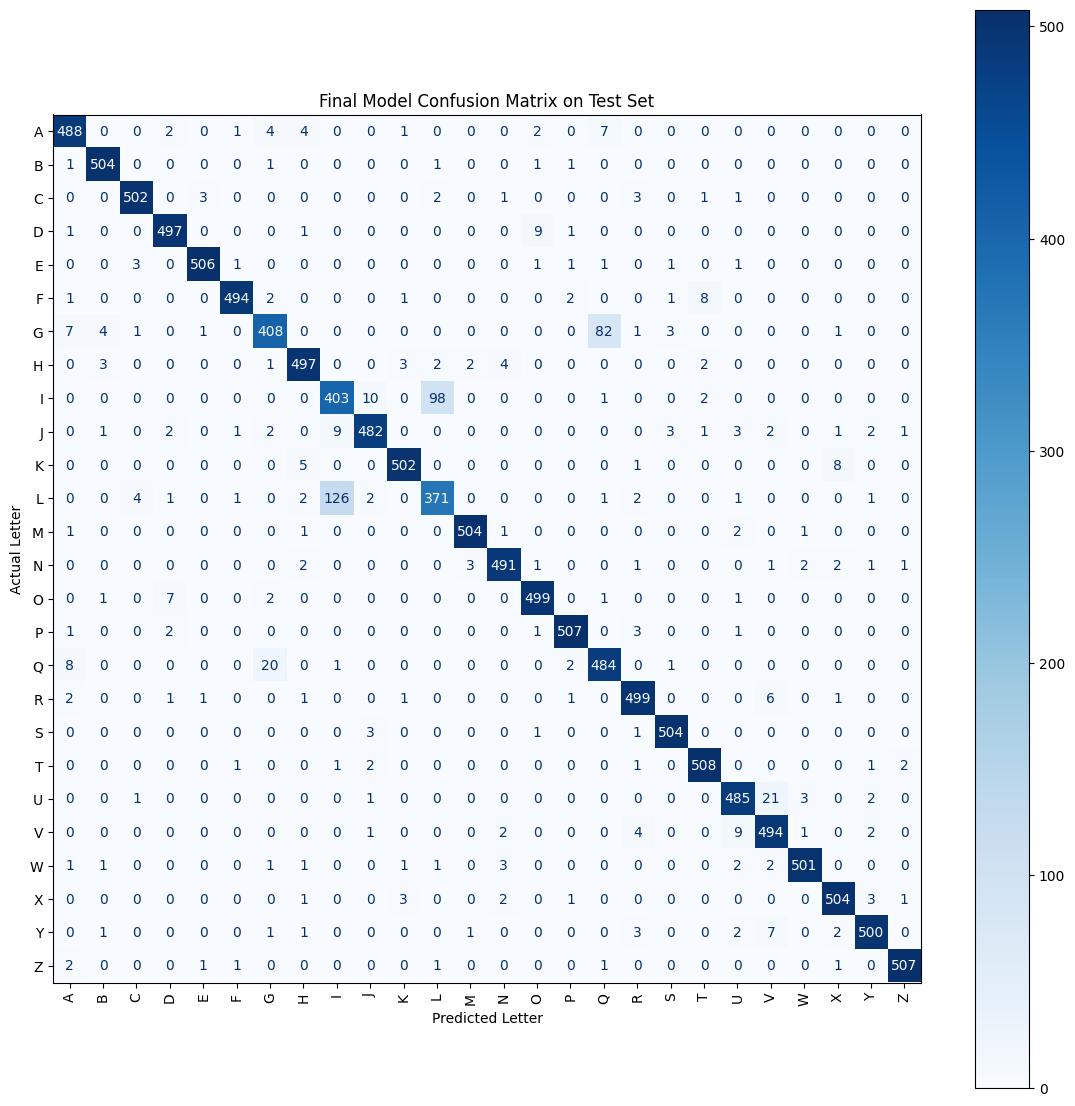

In [30]:
final_cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d", ax=plt.gca())

plt.title("Final Model Confusion Matrix on Test Set")
plt.xlabel("Predicted Letter")
plt.ylabel("Actual Letter")
plt.xticks(rotation=90)
plt.show()

### Final Confusion Matrix Analysis

The confusion matrix shows how the final selected model performed for each letter class on the test set.

Each row represents the actual letter, while each column represents the predicted letter. Values on the diagonal represent correct predictions. Values outside the diagonal represent incorrect predictions.

This matrix is important because it shows the exact pattern of mistakes made by the model. If the model has strong performance, most of the values should be concentrated along the diagonal.

The off-diagonal values show which letters were confused with other letters. This is especially useful for handwritten character recognition because some letters naturally look similar depending on writing style.

For example, possible confusing pairs include:

- I and L
- C and O
- U and V
- M and N
- P and R

The confusion matrix helps evaluate whether the model’s errors are random or concentrated among visually similar classes. If most errors occur between similar-looking letters, the mistakes are more understandable and reflect the difficulty of the classification task.

### Top Confused Pairs

In [31]:
# Remove correct predictions
final_cm_errors = final_cm.copy()
np.fill_diagonal(final_cm_errors, 0)

final_confusion_pairs = []

for actual in range(26):
    for predicted in range(26):
        count = final_cm_errors[actual, predicted]
        
        if count > 0:
            final_confusion_pairs.append({
                "actual_letter": class_names[actual],
                "predicted_letter": class_names[predicted],
                "mistake_count": count
            })

final_confusion_pairs_df = pd.DataFrame(final_confusion_pairs)
final_confusion_pairs_df = final_confusion_pairs_df.sort_values(
    "mistake_count",
    ascending=False
)

display(final_confusion_pairs_df.head(10))

,actual_letter,predicted_letter,mistake_count
73,L,I,126
51,I,L,98
39,G,Q,82
127,U,V,21
104,Q,G,20
50,I,J,10
58,J,I,9
20,D,O,9
133,V,U,9
68,K,X,8


### Final Top Confused Letter Pairs Analysis

The top confused letter pairs table shows the most common mistakes made by the final model on the test set.

The largest source of error is between **L** and **I**:

- Actual **L** predicted as **I**: **126 times**
- Actual **I** predicted as **L**: **98 times**

This confirms that the model struggles most with separating **I** and **L**. This matches the classification report, where **L** and **I** had the lowest F1-scores.

The next major confusion is between **G** and **Q**:

- Actual **G** predicted as **Q**: **82 times**
- Actual **Q** predicted as **G**: **20 times**

This explains why **G** and **Q** also had lower F1-scores. Both letters have rounded shapes, and in handwriting the distinguishing tail may not always be clear.

There is also some confusion between **U** and **V**:

- Actual **U** predicted as **V**: **21 times**
- Actual **V** predicted as **U**: **9 times**

This is understandable because U and V both have similar open shapes.

Other smaller mistakes include **I predicted as J** 10 times, **J predicted as I** 9 times, **D predicted as O** 9 times, and **K predicted as X** 8 times.

Overall, the model’s errors are not random. They are concentrated around visually similar handwritten letters. This suggests that the CNN has learned meaningful letter features but still struggles when two classes have similar shapes.

### Misclassified Examples

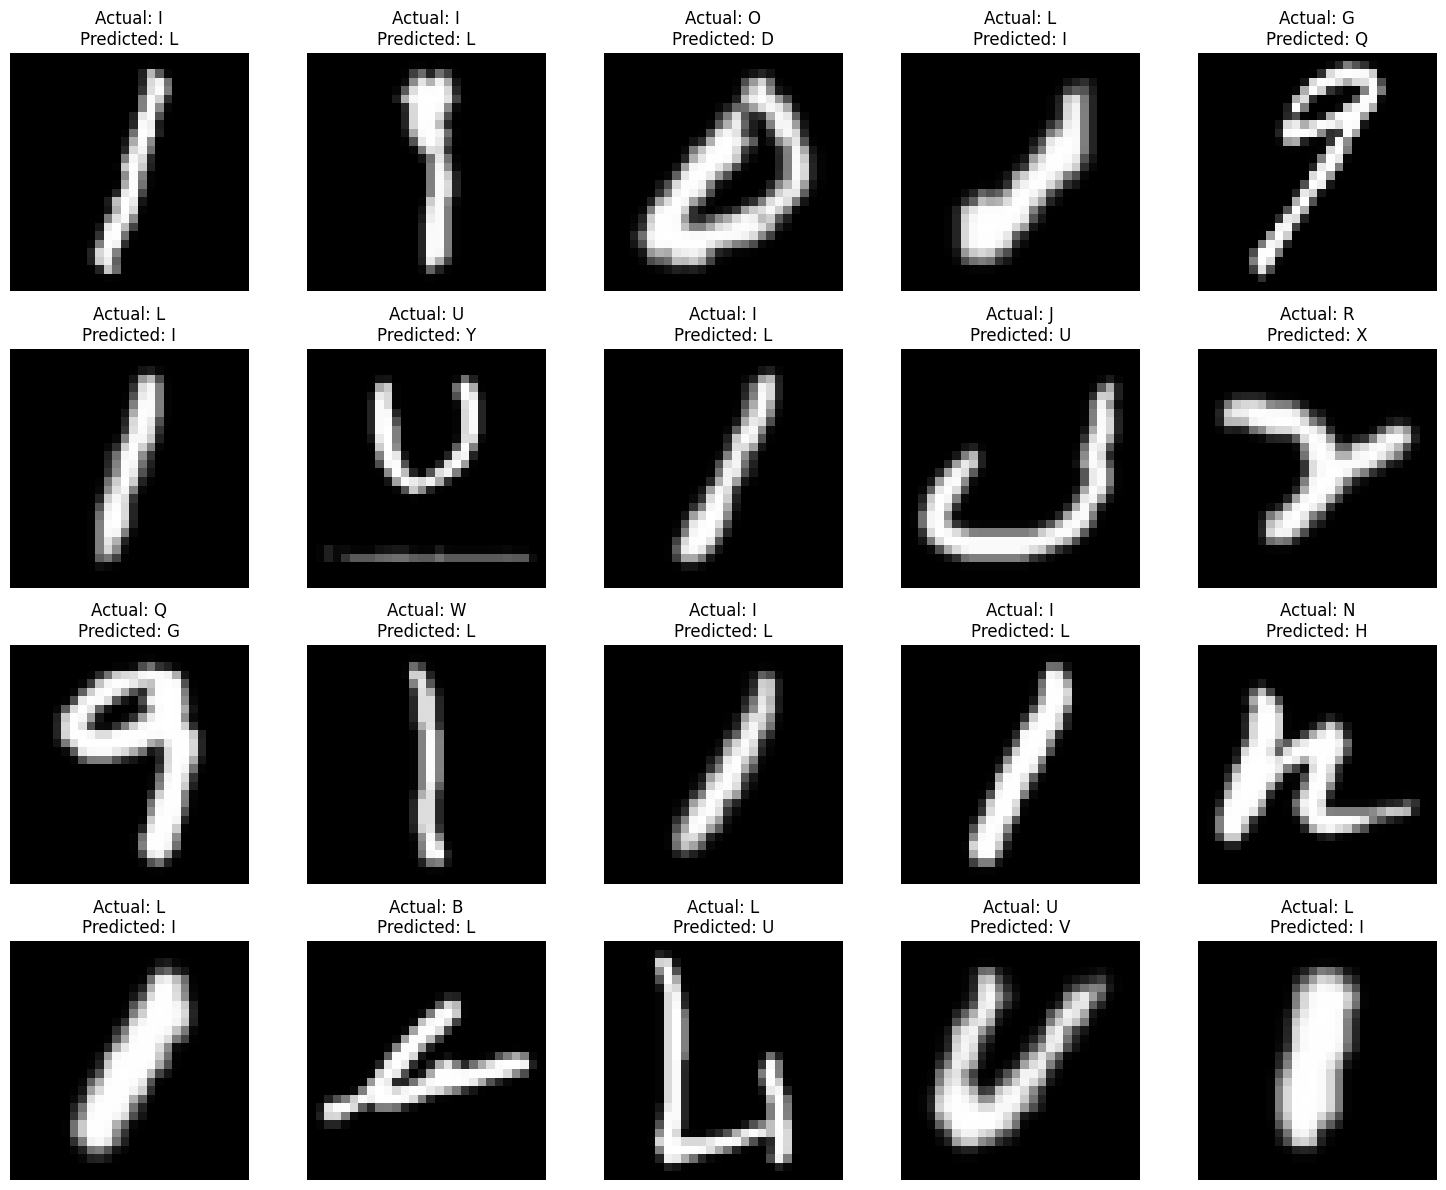

In [32]:
def show_misclassified_examples(X_data, y_true, y_pred, class_names, max_images=20):
    wrong_indices = np.where(y_true != y_pred)[0]
    
    if len(wrong_indices) == 0:
        print("No misclassified examples found.")
        return
    
    chosen_indices = np.random.choice(
        wrong_indices,
        size=min(max_images, len(wrong_indices)),
        replace=False
    )
    
    cols = 5
    rows = int(np.ceil(len(chosen_indices) / cols))
    
    plt.figure(figsize=(cols * 3, rows * 3))
    
    for i, idx in enumerate(chosen_indices):
        actual = class_names[y_true[idx]]
        predicted = class_names[y_pred[idx]]
        
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_data[idx].squeeze(), cmap="gray")
        plt.title(f"Actual: {actual}\nPredicted: {predicted}")
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()


show_misclassified_examples(
    X_test,
    y_test,
    test_pred,
    class_names,
    max_images=20
)

### Misclassified Examples Analysis

The misclassified examples show actual test images that the final model predicted incorrectly. This is useful because it allows the errors to be inspected visually instead of only relying on accuracy and F1-score.

Many of the mistakes are understandable when viewed visually. Handwritten letters can be unclear, tilted, incomplete, or similar to another letter. Since the images are only **28 × 28** pixels, small differences in handwriting may be difficult for the CNN to detect.

From the examples shown, many mistakes match the earlier confusion matrix findings. Several examples involve confusing visually similar letters such as **G/Q**, **I/L**, and **V/U**.

Overall, the misclassified examples confirm that the final model performs well, but still struggles with ambiguous handwriting. The errors are mainly caused by visually similar letter shapes rather than a general failure of the CNN.

### Save Final Best Weights

In [33]:
FINAL_WEIGHTS_PATH = "partA_best_final_model.weights.h5"

# Save the selected model's best weights
best_model.save_weights(FINAL_WEIGHTS_PATH)

print("Final best model:", best_model_name)
print("Best final weights saved to:", FINAL_WEIGHTS_PATH)

Final best model: Fine-Tuned Regularised CNN
Best final weights saved to: partA_best_final_model.weights.h5


### Saving the Best Model Weights

The final selected model weights were saved as:

`partA_best_final_model.weights.h5`

Saving the best weights is important because it allows the model result to be reproduced without retraining the CNN from the beginning. This also follows the assignment requirement to submit the best neural network weights as an `.h5` file.

## 14. Model Demo: Predicting a Letter from an Input Image
After evaluating the final model using test accuracy, F1-score, confusion matrix, and misclassified examples, I created two simple demonstrations to show how the trained CNN can be used in practice.

The purpose of this section is to show the model's input-output behaviour. The model takes a handwritten letter image as input and predicts one of the 26 alphabet classes from A to Z.

Two demos are included:

1. **Single Test Image Demo**  
   This shows the prediction process clearly using one unseen test image.

2. **Random Test Image Demo**  
   This shows the model making predictions on multiple unseen test images, which gives a more realistic view of how it performs across different handwriting styles.


Together, these demos show that the final CNN model is not only evaluated using metrics, but can also be used practically to classify handwritten letter images.

This demo uses the test set, which contains unseen images that were not used during model training.

This shows how the model works in practice:

1. Select one image input.
2. Display the image.
3. Pass the image into the trained CNN.
4. Convert the model’s softmax output into the predicted letter.
5. Show the model’s confidence score.


### Demo using one test image

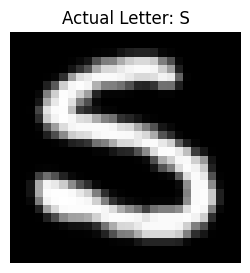

1/1 [==============================] - 0s 157ms/step
Actual Letter: S
Predicted Letter: S
Confidence: 99.99 %


In [34]:
# Choose one test image to demo
demo_index = 0  

demo_image = X_test[demo_index]
demo_true_label = y_test[demo_index]

# Show the input image
plt.figure(figsize=(3, 3))
plt.imshow(demo_image.squeeze(), cmap="gray")
plt.title(f"Actual Letter: {class_names[demo_true_label]}")
plt.axis("off")
plt.show()

# Model prediction
demo_input = np.expand_dims(demo_image, axis=0)

demo_prediction_proba = best_model.predict(demo_input)
demo_predicted_class = np.argmax(demo_prediction_proba)
demo_confidence = np.max(demo_prediction_proba)

print("Actual Letter:", class_names[demo_true_label])
print("Predicted Letter:", class_names[demo_predicted_class])
print("Confidence:", round(demo_confidence * 100, 2), "%")

### Demo Output Analysis

The image above was passed into the final trained CNN model as a single input.

The model produced a probability score for each of the 26 letter classes. The class with the highest probability was selected as the predicted output.

The predicted letter matches the actual letter (prediction = actual = S), the model has classified this sample correctly. The confidence score (**99.99**) shows that the model believes in its prediction very strongly.

This demonstrates that the CNN can take a handwritten letter image as input and return a predicted alphabet class as output.

### Demo using random 10 images 

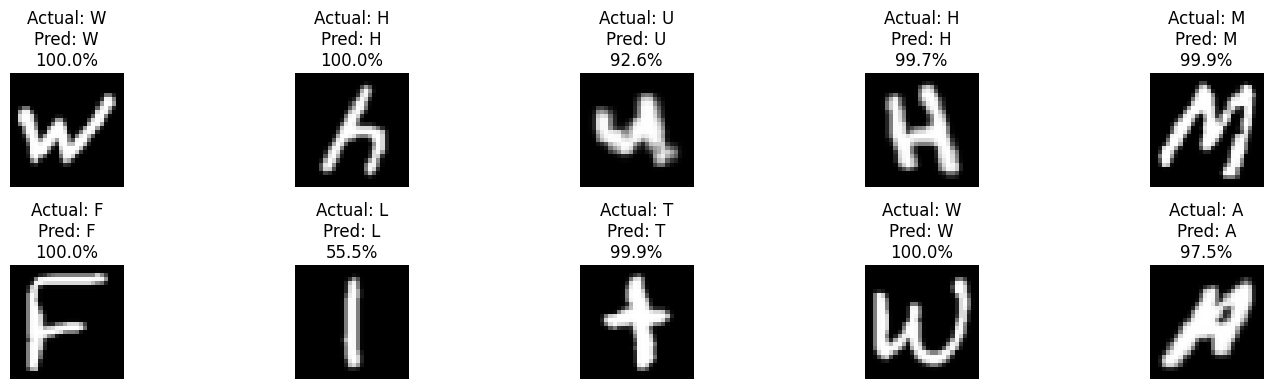

In [35]:
# Random demo of 10 test images
random_indices = np.random.choice(len(X_test), size=10, replace=False)

plt.figure(figsize=(15, 4))

for i, idx in enumerate(random_indices):
    image = X_test[idx]
    true_label = y_test[idx]
    
    prediction_proba = best_model.predict(np.expand_dims(image, axis=0), verbose=0)
    predicted_label = np.argmax(prediction_proba)
    confidence = np.max(prediction_proba)
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(
        f"Actual: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"{confidence * 100:.1f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Model Demo Output Analysis

The model demo shows the final CNN model being tested on random unseen images from the test set.

For each image, the output displays:

- the actual letter,
- the predicted letter,
- and the model’s confidence score.

Most of the examples were predicted correctly, such as **H → H**, **C → C**, **P → P**, **S → S**, **N → N**, **A → A**, **J → J**, and **D → D**. Several of these predictions also had very high confidence, with some reaching close to **100%**. This shows that the model is able to recognise many handwritten letters accurately when the letter shape is clear.

There was also one incorrect prediction where the actual letter was **W**, but the model predicted **B** with **63.0%** confidence. This mistake is understandable because the handwritten W in the image is quite stylised and does not look like a typical printed W. The shape has curved strokes that may have confused the model.

Some correct predictions had lower confidence, such as **H → H** with **56.9%** and **J → J** with **59.6%**. This means the model still selected the correct class, but it was less certain. Lower confidence usually happens when the handwriting is unclear, unusual, or visually similar to other letters.

Overall, this demo proves that the model can take handwritten letter images as input and produce predicted alphabet labels as output. It also shows that the model performs well on clear examples, while uncertainty or mistakes usually occur when the handwriting style is ambiguous.

## Final Conclusion

This notebook built and evaluated CNN models for handwritten letter classification using the provided EMNIST letters dataset.

The dataset was inspected before modelling. I checked the dataset shape, missing values, duplicate rows, label range, class distribution, pixel range, and image orientation. Invalid labels outside the range **1 to 26** were removed because they do not represent valid alphabet classes from A to Z. Duplicate rows were also removed to improve data quality.

The pixel values were reshaped into **28 × 28 × 1** grayscale images and normalised to the range **0 to 1**. The labels were converted from **1–26** to **0–25** so that they could be used with `sparse_categorical_crossentropy`.

A **70% / 15% / 15%** split was used for training, validation, and testing. This gave the CNN enough data to learn from while still keeping separate validation and test sets for fair evaluation. Stratified splitting was used so that all 26 letter classes were represented fairly in each split.

The **Baseline CNN** achieved a best validation accuracy of **93.21%**, but it showed signs of overfitting because the final training accuracy was much higher than the final validation accuracy.

The **Regularised CNN** improved the validation accuracy to **95.27%** and reduced validation loss to **0.1413**. This showed that Batch Normalisation, Dropout, deeper convolutional layers, and Global Average Pooling improved generalisation.

The **Augmented CNN** was tested using small rotations, translations, and zoom changes. It achieved a best validation accuracy of **94.11%**, which was better than the baseline but weaker than the regularised CNN. This showed that augmentation was useful to test, but it was not the strongest improvement for this dataset.

The **Fine-Tuned Regularised CNN** was selected as the final model because it achieved the strongest validation performance, with a best validation accuracy of **95.29%** and the lowest validation loss of **0.1411**.

On the test set, the final model achieved:

- **Test accuracy**: **94.90%**
- **Macro F1-score**: **0.9489**
- **Weighted F1-score**: **0.9489**
- **Correct predictions**: **12,641 out of 13,320**
- **Wrong predictions**: **679 out of 13,320**

The final classification report showed that the model performed very well for most letters. However, it struggled more with **I**, **L**, **G**, and **Q**. The confusion matrix and misclassified examples confirmed that most errors were between visually similar handwritten letters, especially **I/L**, **G/Q**, and **U/V**.

Overall, the final CNN model is suitable for this task because it achieved high test accuracy, balanced F1-scores, and strong generalisation from validation to test data. The remaining errors are mainly due to ambiguous handwriting and low-resolution images, rather than general model weakness.